In [209]:
##### NOTES NOTES NOTES 
#drone(scen_12_cust_20Enhan2IFnewv5correct-2d)
#in this version used drone arrival and departure times for Scenario-4 (v5) 
#reached exactly the same solution with only t variables


In [210]:
#Importing the package numpy as np
import numpy as np
import pandas as pd
# "rnd" is an object that generate random numbers.
rnd = np.random
#set "seed(a number)"
rnd.seed(6465)
import copy

In [211]:
# Number of customers.
n = 12
c = 12
e = 20
# Maximum capacity of the vehicle.
#Q = 20
#The set of nodes without the depot.
#C = [i for i in range(1,n+1)]  #represents the all customers
C = [i for i in range(1,n+1)]  #represents the all customers

#C = [1,2…………c]
N = [i for i in range(0,n+2)] # represents the set of all nodes in the network
#N = [0,1,2,……..c+1)] 
# V = [0]+ N
# A collection that contains the demand of each node.
#q = {i: rnd.randint(1,2) for i in N}


In [212]:
#G = [i for i in range(1,10)]  #represents the d
# updating G and using it in a different way to see the result
G = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]

In [213]:
G1 = [4,5]

In [214]:
G2 = [1, 2, 3, 6, 7, 8, 9, 10, 11, 12]

In [215]:
N0 = [i for i in range(0,n+1)] 
#N0 = [0,1,2……………………c] represents the set of nodes from which a vehicle may depart

N1 = [i for i in range(1,n+2)] 
#N1 = [1,2……………………c+1] represents the set of nodes to which a vehicle may visit during the course of a tour
N0
N1

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]

In [216]:
#C should go from 1 to n
#N should go from 0 to n+1
#N0 from 0 to n
#N1 from 1 to n+1
#A from i in N0 to j in N1
#D from i in N0 to j in C to k in N1
#You are defining small c and never using it.


NameError: name 'q' is not defined

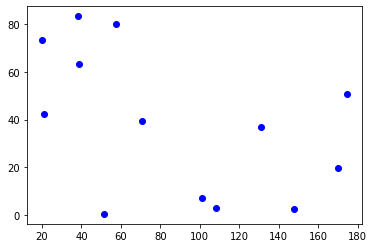

In [217]:
# Generating random numbers between (0 and 15) * 200.
loc_x = rnd.rand(len(N))*200
# Generating random numbers between (0 and 15) * 100.
loc_y = rnd.rand(len(N))*100
#Importing the package matplotlib.pyplot as plt.
import matplotlib.pyplot as plt
#Plotting the n nodes without the node 0 (depot) and chose the color blue for each node.
plt.scatter(loc_x[1:],loc_y[1:],c='b')
for i in N:
    plt.annotate('$q_%d=%d$'%(i,q[i]),(loc_x[i]+2,loc_y[i]))
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
plt.axis('equal');



In [218]:
loc_x

array([ 32.64653321,  20.92042941,  70.51730618,  51.42557655,
       108.11531198,  57.33442965, 169.93501477, 130.9077813 ,
       101.15247964, 147.45312482,  20.08328288,  38.53843776,
        38.3957013 , 174.31901135])

In [219]:
loc_y

array([62.17079298, 42.3991275 , 39.6315991 ,  0.55748748,  3.22543122,
       79.99903715, 19.66124136, 37.00538935,  7.39662907,  2.41999461,
       73.50859535, 63.11703238, 83.2561704 , 50.54223648])

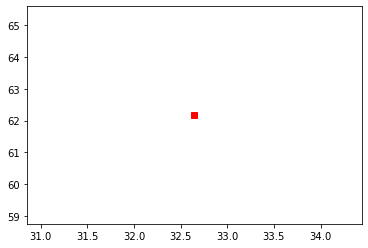

In [220]:
#Ploting the node 0, chosing the red like its color and the square form like a marker.
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
# additional
#plt.axis (‘equal’);


In [221]:
#Showing the Initial plot.
plt.show()


In [222]:
#Intializing the set of arcs A.
# A = [(i,j) for i in V for j in V if i!=j]
#08252020UPDATE A = [(i,j) for i in N for j in N if i!=j]
A = [(i,j) for i in N0 for j in N1 if i!=j]
#Defining and computing the distances which will be used as truck's travel time
#c= {(i,j):np.hypot(loc_x[i]-loc_x[j],loc_y[i]-loc_y[j]) for i,j in A}


In [223]:
#generating random uniform or creating random uniform
az =np.random.uniform(0, 10, size=(13,2))
az

array([[5.95170797, 0.96235038],
       [0.92268591, 1.34567673],
       [4.37388962, 0.65050658],
       [5.05534783, 8.50809268],
       [7.46580556, 9.65303097],
       [9.63509374, 6.60995059],
       [2.57185724, 0.5459453 ],
       [1.72609113, 9.86586521],
       [6.61882771, 1.99329564],
       [6.29890048, 3.68558095],
       [3.39667706, 0.53881414],
       [0.6860028 , 2.34039385],
       [2.0353991 , 6.00637645]])

In [224]:
#final version for generation
ads = np.round(az,2).tolist()
ads.insert(13, ads[0])
ads, len(ads)
#ads=a.tolist()

([[5.95, 0.96],
  [0.92, 1.35],
  [4.37, 0.65],
  [5.06, 8.51],
  [7.47, 9.65],
  [9.64, 6.61],
  [2.57, 0.55],
  [1.73, 9.87],
  [6.62, 1.99],
  [6.3, 3.69],
  [3.4, 0.54],
  [0.69, 2.34],
  [2.04, 6.01],
  [5.95, 0.96]],
 14)

In [225]:
ads[13]

[5.95, 0.96]

In [226]:
#15-customer v10 scenario coordinates
#original first 12-customer data = data = [[5, 7], [7, 3], [8, 1], [1, 4], [4, 3], [1.2, 2.3], [3, 4.9], [0.5, 6.1], [0.8, 5.4], [2.7, 6.7], [3.8, 5.9], [1.8, 7.6], [2.3, 8.3], [5, 7]]
#original data = [[5, 7], [7, 3], [8, 1], [1, 4], [4, 3], [1.2, 2.3], [3, 4.9], [0.5, 6.1], [0.8, 5.4], [2.7, 6.7], [3.8, 5.9], [1.8, 7.6], [2.3, 8.3], [5, 7]]
#12-CUSTOMER data for the disruption at t= 15 when drone is between 4 and 2 and truck is between 4 and 5
#data = [[8, 5], [4, 6.5], [3.5, 7.5], [4.5, 9.5], [8, 9.5], [10.5, 8], [10, 6], [11, 4], [9, 3], [7, 2.5], [5, 1.5], [4, 3], [3.5,4.5], [8,5]]
data = ads
ctys = ['0', '1', '2','3', '4', '5', '6', '7', '8', '9', '10', '11','12', '13']
df = pd.DataFrame(data, columns=['xcord', 'ycord'], index=ctys)

In [227]:
import math
mnm = data
from collections import defaultdict
# initializing dict with lists
dronev2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue
        
        dronev2[(i, j)] = ((math.sqrt((mnm[i][0] - mnm[j][0])**2 + (mnm[i][1] - mnm[j][1])**2))*60)/35
        #dronev2[(i, j)] = 500
z2 = dronev2
z2
    

defaultdict(list,
            {(0, 1): 8.648737078974278,
             (0, 2): 2.7602129465322203,
             (0, 3): 13.032473099992986,
             (0, 4): 15.123313533908432,
             (0, 5): 11.568393252694152,
             (0, 6): 5.8367589552799615,
             (0, 7): 16.90084890996754,
             (0, 8): 2.106410042063539,
             (0, 9): 4.7183047803210005,
             (0, 10): 4.430325919737965,
             (0, 11): 9.322310303125246,
             (0, 12): 10.948717565383198,
             (0, 13): 0.0,
             (1, 2): 6.0347970562566635,
             (1, 3): 14.178417631407683,
             (1, 4): 18.12548099291409,
             (1, 5): 17.45762449651225,
             (1, 6): 3.143506426438671,
             (1, 7): 14.671571845176071,
             (1, 8): 9.832829642351697,
             (1, 9): 10.057467527226944,
             (1, 10): 4.472446255708847,
             (1, 11): 1.7423418441972904,
             (1, 12): 8.216061919763492,
             (1, 

In [228]:
mnm = data
from collections import defaultdict
# initializing dict with lists
truckv2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue        
        truckv2[(i, j)] = ((abs(mnm[i][0] - mnm[j][0])+ abs(mnm[i][1] - mnm[j][1]))*60)/25
z1 = truckv2
z1

defaultdict(list,
            {(0, 1): 13.008,
             (0, 2): 4.5360000000000005,
             (0, 3): 20.256000000000004,
             (0, 4): 24.504,
             (0, 5): 22.416,
             (0, 6): 9.096,
             (0, 7): 31.512000000000004,
             (0, 8): 4.08,
             (0, 9): 7.3919999999999995,
             (0, 10): 7.128000000000001,
             (0, 11): 15.936,
             (0, 12): 21.504,
             (0, 13): 0.0,
             (1, 2): 9.96,
             (1, 3): 27.12,
             (1, 4): 35.64000000000001,
             (1, 5): 33.552,
             (1, 6): 5.88,
             (1, 7): 22.392,
             (1, 8): 15.216,
             (1, 9): 18.528,
             (1, 10): 7.896,
             (1, 11): 2.9279999999999995,
             (1, 12): 13.872,
             (1, 13): 13.008,
             (2, 1): 9.96,
             (2, 3): 20.519999999999996,
             (2, 4): 29.04,
             (2, 5): 26.952,
             (2, 6): 4.560000000000001,
             (

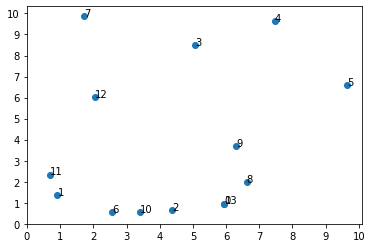

In [229]:
# drone(scen_15_cust_20-2IFdisratt15v5-2dROLLINGOLDOLDO-OLD OLD OLD OLD OLD OLD OLD )
data1 = data
#loc_x = [7, 4.5, 5, 4.5, 8, 10.5, 8.1, 11, 7, 5, 4, 3.5, 9 ]
x1=[]
y1= []
for i in range (len(data1)):
    #for j in range (2):
    x1.append(data1 [i][0])
    y1.append(data1 [i][1])

# Generating random numbers between (0 and 15) * 100.
#loc_y = rnd.rand(len(N))*100


#drone(scen_15_cust_20En2IF-v20disrt15vrolling) scenario nodes
import matplotlib.pyplot as plt

x = x1
y = y1

#n=['0', '1', '2','3', '4', '5', '6', '7', '8', '9' ]
numcity= ctys
fig, ax = plt.subplots()
ax.scatter(x, y)
#x1 = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,1,17,18,19,20]
#values = range(len(x1))
#plt.xticks([0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20])
plt.xticks([0,1,2,3,4,5,6,7,8,9,10])
plt.yticks([0,1,2,3,4,5,6,7,8,9,10])
for i, txt in enumerate(numcity):
    ax.annotate(txt, (x [i], y [i]))

plt.show()

In [230]:
#Importing the docplex.mp.model from the CPLEX as Model
from docplex.mp.model import Model
mdl = Model('CVRP')


In [231]:
#Initializing our binary variable x_i,j if the truck travels from node i to node j
x=mdl.binary_var_dict (A,name='x')
#Initializing our cumulative demand u
# IN 11 COMMENT ONLY u=mdl.continuous_var_dict (N,ub=Q ,name = 'u')


In [232]:
#drone launch and serve binary variable 
g=mdl.binary_var_dict (A,name='g')

In [233]:
#drone rendezvous and serve binary variable 
h=mdl.binary_var_dict (A,name='h')

In [234]:
#Initializing our binary variable y_i,j,k the drone travels from node i to node j
# OLD IN 11 COMMENTED used at the start y=mdl.binary_var_dict (A,name='y')

In [235]:
#Initializing our binary variable p_i,j if customer i is visited at some time before customer j in the truck's path
#ACTIVE p=mdl.binary_var_dict (A,name='p')

In [236]:
#Initializing variable wi (Dr.Murray's ui) subtour elimination constraints (definition for Constraint 5)
#ACTIVE u=mdl.continuous_var_dict(N,ub=n+2 , lb =1, name = 'u')

In [237]:
#3IF new formulation (FIRST VERSION OF w WORKING)
#w=mdl.continuous_var_dict(C,ub=200, lb =0, name = 'w')
#w

In [238]:
#w definition as a list like t and d (second trial)
w=mdl.continuous_var_list (n+2, ub=1000 , lb =0, name = 'w') #3IF
#w=mdl.continuous_var_list (n+2, name = 'w') #3IF
#mdl.add_constraint(w[0] == 0, ctname = 'aww3IF') #3IF Constraint 12

In [239]:
#3IF z instead of z, v is used
v=mdl.binary_var_dict (N,name='v')


In [240]:
#3IF z instead of z, v is used
m = mdl.binary_var_dict (N,name='m')


In [241]:
#3IF z instead of z, v is used
m2 = mdl.binary_var_dict (N,name='m2')

In [242]:
#(u[1]+2)*3 just to see how dictionary works

In [243]:
#08252020UPDATE D = [(i,j,k) for i in N0 for j in N1 for k in N1 if i!=j if i!=k if j!=k]
#D = [(i,j,k) for i in N0 for j in C for k in N1 if i!=j if i!=k if j!=k]
D = [(i,j,k) for i in N0 for j in G2 for k in N1 if i!=j if i!=k if j!=k]


In [244]:
#NOT NEEDED FOR 2-IF
#Initializing our binary variable y_i,j,k
#drone may launch from any particular node, at most once (Dr.Murray's - Constraint 7-three indices)
#LAST VERSIONy=mdl.binary_var_dict (D,name='y')

In [245]:
#08252020 update DISABLED
#t[i] = (sum(c[i,j]*x[i,j]) for i,j in A)
# t[i] = (sum(t) for i,j in A)    
#ORIGINALt=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't')
#ORIGINALmdl.add_constraint(t[0] == 0, ctname = 'ac') 
#t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF
#mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12
#t

In [246]:

#mdl.add_constraint(t0 == 0, ctname = 'ac3IF ') #3IF Constraint 12
#t_0 == 0 
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12


docplex.mp.LinearConstraint[ac3IF](t_0,EQ,0)

In [247]:
#08252020 update DISABLED
#t[i] = (sum(c[i,j]*x[i,j]) for i,j in A)
# t[i] = (sum(t) for i,j in A)    
#ORIGINALt=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't')
#ORIGINALmdl.add_constraint(t[0] == 0, ctname = 'ac') 
#t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
d = mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 'd') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF
#mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12
#t

In [248]:
#mdl.add_constraint(t0 == 0, ctname = 'ac3IF ') #3IF Constraint 12
#t_0 == 0 
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(d[0] == 0, ctname = 'dddef2IF') #3IF Constraint 12


docplex.mp.LinearConstraint[dddef2IF](d_0,EQ,0)

In [249]:
#08252020 update DISABLED
#t[i] = (sum(c[i,j]*x[i,j]) for i,j in A)
# t[i] = (sum(t) for i,j in A)    
#ORIGINALt=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't')
#ORIGINALmdl.add_constraint(t[0] == 0, ctname = 'ac') 
#t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
d1 = mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 'd1') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF
#mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12
#t

In [250]:
#mdl.add_constraint(t0 == 0, ctname = 'ac3IF ') #3IF Constraint 12
#t_0 == 0 
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(d1[0] == 0, ctname = 'dddEPef2IF') #3IF Constraint 12


docplex.mp.LinearConstraint[dddEPef2IF](d1_0,EQ,0)

In [251]:
mdl.add_constraints(((mdl.sum(h[i,j] for i in G2 if i != j) == m[j] ) for j in N1 if j != 0  ), names = 'cDR2IF28d92IF')

[docplex.mp.LinearConstraint[cDR2IF28d92IF1](h_2_1+h_3_1+h_6_1+h_7_1+h_8_1+h_9_1+h_10_1+h_11_1+h_12_1,EQ,m_1),
 docplex.mp.LinearConstraint[cDR2IF28d92IF2](h_1_2+h_3_2+h_6_2+h_7_2+h_8_2+h_9_2+h_10_2+h_11_2+h_12_2,EQ,m_2),
 docplex.mp.LinearConstraint[cDR2IF28d92IF3](h_1_3+h_2_3+h_6_3+h_7_3+h_8_3+h_9_3+h_10_3+h_11_3+h_12_3,EQ,m_3),
 docplex.mp.LinearConstraint[cDR2IF28d92IF4](h_1_4+h_2_4+h_3_4+h_6_4+h_7_4+h_8_4+h_9_4+h_10_4+h_11_4+h_12_4,EQ,m_4),
 docplex.mp.LinearConstraint[cDR2IF28d92IF5](h_1_5+h_2_5+h_3_5+h_6_5+h_7_5+h_8_5+h_9_5+h_10_5+h_11_5+h_12_5,EQ,m_5),
 docplex.mp.LinearConstraint[cDR2IF28d92IF6](h_1_6+h_2_6+h_3_6+h_7_6+h_8_6+h_9_6+h_10_6+h_11_6+h_12_6,EQ,m_6),
 docplex.mp.LinearConstraint[cDR2IF28d92IF7](h_1_7+h_2_7+h_3_7+h_6_7+h_8_7+h_9_7+h_10_7+h_11_7+h_12_7,EQ,m_7),
 docplex.mp.LinearConstraint[cDR2IF28d92IF8](h_1_8+h_2_8+h_3_8+h_6_8+h_7_8+h_9_8+h_10_8+h_11_8+h_12_8,EQ,m_8),
 docplex.mp.LinearConstraint[cDR2IF28d92IF9](h_1_9+h_2_9+h_3_9+h_6_9+h_7_9+h_8_9+h_10_9+h_11_9+h_12_

In [252]:
#ORIGINAL mdl.add_constraints(((mdl.sum(g[i,j] for j in N1 if i != j) == m2[i] ) for i in N0 if i != 0 ), names = 'cDR3IF28d92IF')
mdl.add_constraints(((mdl.sum(g[i,j] for j in N1 if i != j) == m2[i] ) for i in N0 if i != 0 if i != n+1), names = 'cDR3IF28d92IF')


[docplex.mp.LinearConstraint[cDR3IF28d92IF1](g_1_2+g_1_3+g_1_4+g_1_5+g_1_6+g_1_7+g_1_8+g_1_9+g_1_10+g_1_11+g_1_12+g_1_13,EQ,m2_1),
 docplex.mp.LinearConstraint[cDR3IF28d92IF2](g_2_1+g_2_3+g_2_4+g_2_5+g_2_6+g_2_7+g_2_8+g_2_9+g_2_10+g_2_11+g_2_12+g_2_13,EQ,m2_2),
 docplex.mp.LinearConstraint[cDR3IF28d92IF3](g_3_1+g_3_2+g_3_4+g_3_5+g_3_6+g_3_7+g_3_8+g_3_9+g_3_10+g_3_11+g_3_12+g_3_13,EQ,m2_3),
 docplex.mp.LinearConstraint[cDR3IF28d92IF4](g_4_1+g_4_2+g_4_3+g_4_5+g_4_6+g_4_7+g_4_8+g_4_9+g_4_10+g_4_11+g_4_12+g_4_13,EQ,m2_4),
 docplex.mp.LinearConstraint[cDR3IF28d92IF5](g_5_1+g_5_2+g_5_3+g_5_4+g_5_6+g_5_7+g_5_8+g_5_9+g_5_10+g_5_11+g_5_12+g_5_13,EQ,m2_5),
 docplex.mp.LinearConstraint[cDR3IF28d92IF6](g_6_1+g_6_2+g_6_3+g_6_4+g_6_5+g_6_7+g_6_8+g_6_9+g_6_10+g_6_11+g_6_12+g_6_13,EQ,m2_6),
 docplex.mp.LinearConstraint[cDR3IF28d92IF7](g_7_1+g_7_2+g_7_3+g_7_4+g_7_5+g_7_6+g_7_8+g_7_9+g_7_10+g_7_11+g_7_12+g_7_13,EQ,m2_7),
 docplex.mp.LinearConstraint[cDR3IF28d92IF8](g_8_1+g_8_2+g_8_3+g_8_4+g_8_5+g_8_6+g_

In [253]:
mdl.add_constraint(m2[n+1] == 0, ctname = 'dddN13ef2IF') #ADDITIONAL m2 constraint node 13 will never be launch point

docplex.mp.LinearConstraint[dddN13ef2IF](m2_13,EQ,0)

In [254]:
#mdl.add_constraints(((g[i,j]+ g[j,i]) <= (1) for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (11,j) if (j,i) != (11,i) ) , names = 'C36kd2IFdc')
#FATHOM mdl.add_constraints((g[i,j] == 0 for (i,j) in A if z2[i,j]  > 20 ) , names = 'Cin1kd2IFdc')

In [255]:
#3-IF Constraint 3 part:1 (SAME FOR THE 2-IF)
#truck departs from the depot exactly once (Constraint 3)(CM)
#Dr.Silva last update mdl.add_constraints(mdl.sum(x[0,j] for j in N if j != 0) ==1 
#WORKS TOO-3 mdl.add_constraints(mdl.sum(x[0,j] for j in N if j != 0) ==1 for j in N)
# WORKS LAST mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#WORKS MOST RECENT mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#08252020(v23-270)mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0)== 1 for j in N1)
#RECENT MOST UPDATE modified as follow mdl.add_constraints(mdl.sum(x[0,j] for j in N1)== 1)
#mdl.add_constraint(mdl.sum(x[0,j] for j in N1)== 1, ctname = 'b')
#3-IF original mdl.add_constraint(mdl.sum(x[0,j] for j in N1 )== 1, ctname = 'b3IF')
mdl.add_constraint((mdl.sum(x[0,j] for j in N1 if j != n+1 )== 1), ctname = 'b3IF')


docplex.mp.LinearConstraint[b3IF](x_0_1+x_0_2+x_0_3+x_0_4+x_0_5+x_0_6+x_0_7+x_0_8+x_0_9+x_0_10+x_0_11+x_0_12,EQ,1)

In [256]:
#ADDITIONAL-1 
mdl.add_constraint((mdl.sum(x[0,n+1]  )== 0), ctname = 'bAD3IF')

docplex.mp.LinearConstraint[bAD3IF](x_0_13,EQ,0)

In [257]:
#ADDITIONAL-2
#mdl.add_constraint(((g[0,4] )  == 0 ), ctname = '1bAD2dr2IF')
#mdl.add_constraint(((g[0,5] )  == 0 ), ctname = 'bAD2dr2IF')

In [258]:
#ADDITIONAL-3
#mdl.add_constraint(((g[0,5] )  == 0 ), ctname = 'bAD2dr2IF')

In [259]:
#ADDITIONAL-2
#mdl.add_constraint(((g[i,j] for (i,j) in A if (i, j) == (i, 4) if (i,j) == (i,5))  == 0 ), ctname = 'bAD2dr2IF')
mdl.add_constraints((g[i,j]   == 0 for i in N0 for j in G1 if i != j ), names = 'myD2dr2IF')
#mdl.add_constraints((y[i,j,k] == 0 for i in N0 for k in N1 for j in G1 if i != j if i != k if j != k) , names='gg')

[docplex.mp.LinearConstraint[myD2dr2IF1](g_0_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF2](g_0_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF3](g_1_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF4](g_1_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF5](g_2_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF6](g_2_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF7](g_3_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF8](g_3_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF9](g_4_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF10](g_5_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF11](g_6_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF12](g_6_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF13](g_7_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF14](g_7_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF15](g_8_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF16](g_8_5,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF17](g_9_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF18](g_9_5,EQ,0),
 docplex.mp.LinearC

In [260]:
#ALTERNATIVE TRUCK ONLY SOLUTION stop100 phase1
#ALTERNATIVE TRUCK ONLY SOLUTION 
#ALTERNATIVE TRUCK ONLY SOLUTION 
## mdl.add_constraints((g[i,j]   == 0 for i in N0 for j in G2 if i != j ), names = 'myD2dr2IF')

In [261]:
#3-IF Constraint 3 part:2 (SAME FOR THE 2-IF )
#truck returns the depot exactly once (Constraint 4)(altered a bit)
#mdl.add_constraints(mdl.sum(x[0,i])for i in range N) ==1)
#mdl.add_constraints(mdl.sum(x[j,0] for j in range (n+1) if j!=0)==1 for j in N)
# WORKS TOO mdl.add_constraints((mdl.sum(x[j,0] for j in range (n+1) if j!=0)) ==1 for j in N)
# WORKS previous (mdl.add_constraints(mdl.sum(x[j,0])  == 1)for j in range (n+1) if j!=0)
#WORKS PREVIOUS mdl.add_constraints(mdl.sum(x[j,0] for j in N if j != 0 )  == 1 for j in N if j!=0)
# WORKS LAST mdl.add_constraints(mdl.sum(x[j,11] for j in N if j != 0 if j != 11)  == 1 for j in N if j!=0)
#mdl.add_constraints(mdl.sum(x[j,11] for j in N if j != 0 if j != 11)== 1 for j in N)
# WORKS MOST RECENT mdl.add_constraints(mdl.sum(x[j,11] for j in N0 if j != 0 if j != 11)== 1 for j in N0)
#mdl.add_constraints((mdl.sum(x[j,11] for j in N0 if j != 0 if j != 11)== 1) for j in N0)
#08252020(v23-271)mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11)== 1 for i in N0)
# (MOST RECENT UPDATE modified below) mdl.add_constraints(mdl.sum(x[i,11] for i in N0)== 1)
#mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11) == 1 for i in N0)
#mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11) == 1)
#mdl.add_constraint(mdl.sum(x[i,11] for i in N0)== 1, ctname = 'c')
#mdl.add_constraint(mdl.sum(x[i,11] for i in N0 if i != 0)== 1, ctname = 'c3IF')
mdl.add_constraint((mdl.sum(x[i,n+1] for i in N0 if i != 0) == 1), ctname = 'c3IF')

docplex.mp.LinearConstraint[c3IF](x_1_13+x_2_13+x_3_13+x_4_13+x_5_13+x_6_13+x_7_13+x_8_13+x_9_13+x_10_13+x_11_13+x_12_13,EQ,1)

In [262]:
#3-IF Constraint 4 (a bit similar to CM Const6 but different) (SAME FOR THE 2-IF)
#truck flow conservation constraint
#mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,k] for k in N1 if j!=k) for j in C), names = 'e') #CM -6
#mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,i] ) for j in C), names = 'e3IF') # working
#mdl.add_constraints((mdl.sum(x[i,j] for i in A if i!=j) == mdl.sum(x[j,i] for i in A if i!=j ) for j in C ), names = 'e3IF') #3IF normal but not working
#WORKING PREVIOUSLY mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,i] for i in N1 if i!=j) for j in C), names = 'e3IF') # working but not original 3IF
#MOST RECENT mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A ) == mdl.sum(x[j,i] for (j,i) in A ) for j in C ), names = 'e3IF') #3IF normal but not working
mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j ) == mdl.sum(x[j,i] for i in N1 if i != j ) for j in C ), names = 'e3IF') #3IF normal but not working

[docplex.mp.LinearConstraint[e3IF1](x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1+x_10_1+x_11_1+x_12_1,EQ,x_1_2+x_1_3+x_1_4+x_1_5+x_1_6+x_1_7+x_1_8+x_1_9+x_1_10+x_1_11+x_1_12+x_1_13),
 docplex.mp.LinearConstraint[e3IF2](x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2+x_10_2+x_11_2+x_12_2,EQ,x_2_1+x_2_3+x_2_4+x_2_5+x_2_6+x_2_7+x_2_8+x_2_9+x_2_10+x_2_11+x_2_12+x_2_13),
 docplex.mp.LinearConstraint[e3IF3](x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3+x_10_3+x_11_3+x_12_3,EQ,x_3_1+x_3_2+x_3_4+x_3_5+x_3_6+x_3_7+x_3_8+x_3_9+x_3_10+x_3_11+x_3_12+x_3_13),
 docplex.mp.LinearConstraint[e3IF4](x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4+x_10_4+x_11_4+x_12_4,EQ,x_4_1+x_4_2+x_4_3+x_4_5+x_4_6+x_4_7+x_4_8+x_4_9+x_4_10+x_4_11+x_4_12+x_4_13),
 docplex.mp.LinearConstraint[e3IF5](x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5+x_10_5+x_11_5+x_12_5,EQ,x_5_1+x_5_2+x_5_3+x_5_4+x_5_6+x_5_7+x_5_8+x_5_9+x_5_10+x_5_11+x_5_12+x_5_13),
 docplex.mp.LinearConstraint[e3IF6](x_0_

In [263]:
#Constraint-5 3IF (SAME FOR THE 2-IF)
#CM-constraint 19 was used to generate this constraint
#works too mdl.add_constraints(((t[j]  - t[i]  >= z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
#WORKING TOO mdl.add_constraints(((t[j]  >= t[i] +z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
##ORIGINAL mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] - 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials
mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] + m2[j] + m[j]- 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials

[docplex.mp.LinearConstraint[ap3IF1](t_1,GE,10000x_0_1+m_1+m2_1+t_0-9986.992),
 docplex.mp.LinearConstraint[ap3IF2](t_2,GE,10000x_0_2+m_2+m2_2+t_0-9995.464),
 docplex.mp.LinearConstraint[ap3IF3](t_3,GE,10000x_0_3+m_3+m2_3+t_0-9979.744),
 docplex.mp.LinearConstraint[ap3IF4](t_4,GE,10000x_0_4+m_4+m2_4+t_0-9975.496),
 docplex.mp.LinearConstraint[ap3IF5](t_5,GE,10000x_0_5+m_5+m2_5+t_0-9977.584),
 docplex.mp.LinearConstraint[ap3IF6](t_6,GE,10000x_0_6+m_6+m2_6+t_0-9990.904),
 docplex.mp.LinearConstraint[ap3IF7](t_7,GE,10000x_0_7+m_7+m2_7+t_0-9968.488),
 docplex.mp.LinearConstraint[ap3IF8](t_8,GE,10000x_0_8+m_8+m2_8+t_0-9995.920),
 docplex.mp.LinearConstraint[ap3IF9](t_9,GE,10000x_0_9+m_9+m2_9+t_0-9992.608),
 docplex.mp.LinearConstraint[ap3IF10](t_10,GE,10000x_0_10+m_10+m2_10+t_0-9992.872),
 docplex.mp.LinearConstraint[ap3IF11](t_11,GE,10000x_0_11+m_11+m2_11+t_0-9984.064),
 docplex.mp.LinearConstraint[ap3IF12](t_12,GE,10000x_0_12+m_12+m2_12+t_0-9978.496),
 docplex.mp.LinearConstraint[ap3IF13]

In [264]:
#t[i] ADDITION-1
#NEW t[i] definition
# DEACTIVATED mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] >= t[i] + m[i] + m2[i]) for (i,j) in A if j != 0 if i != 0 )


In [265]:
#constraint-7 (SAME FOR THE 2-IF )(3IF)if drone arrive at a node after the truck, truck must wait that is imposed by this constraint
#mdl.add_constraints((w[i] >= t[j] - t[i] - z1[i,j] - 10000*(1- x[i,j])  for i in C for j in N1 if i != j ), names = 'd73IF')
#WORKING mdl.add_constraints((w[i] >= t[j] - t[i] - z1[i,j] - 10000*(1- x[i,j])  for i in C for j in N1 if i != j), names = 'd73IF')
mdl.add_constraints((w[j] >= t[j] - t[i] - m2[j]- m[j] - z1[i,j] - 10000*(1- x[i,j])  for (i,j) in A ), names = 'd73IF')


[docplex.mp.LinearConstraint[d73IF1](w_1,GE,10000x_0_1-m_1-m2_1-t_0+t_1-10013.008),
 docplex.mp.LinearConstraint[d73IF2](w_2,GE,10000x_0_2-m_2-m2_2-t_0+t_2-10004.536),
 docplex.mp.LinearConstraint[d73IF3](w_3,GE,10000x_0_3-m_3-m2_3-t_0+t_3-10020.256),
 docplex.mp.LinearConstraint[d73IF4](w_4,GE,10000x_0_4-m_4-m2_4-t_0+t_4-10024.504),
 docplex.mp.LinearConstraint[d73IF5](w_5,GE,10000x_0_5-m_5-m2_5-t_0+t_5-10022.416),
 docplex.mp.LinearConstraint[d73IF6](w_6,GE,10000x_0_6-m_6-m2_6-t_0+t_6-10009.096),
 docplex.mp.LinearConstraint[d73IF7](w_7,GE,10000x_0_7-m_7-m2_7-t_0+t_7-10031.512),
 docplex.mp.LinearConstraint[d73IF8](w_8,GE,10000x_0_8-m_8-m2_8-t_0+t_8-10004.080),
 docplex.mp.LinearConstraint[d73IF9](w_9,GE,10000x_0_9-m_9-m2_9-t_0+t_9-10007.392),
 docplex.mp.LinearConstraint[d73IF10](w_10,GE,10000x_0_10-m_10-m2_10-t_0+t_10-10007.128),
 docplex.mp.LinearConstraint[d73IF11](w_11,GE,10000x_0_11-m_11-m2_11-t_0+t_11-10015.936),
 docplex.mp.LinearConstraint[d73IF12](w_12,GE,10000x_0_12-m_12-m

In [266]:
#constraint-9 (3IF)drone battery endurance constraints (SAME FOR THE 2-IF)
#WORKING mdl.add_constraints((v[i] <= mdl.sum(x[i,j] for i in N0 if i!=j)for j in C ), names = 'd93IF')
#LAST VERSION OF THE 3-IF mdl.add_constraints((v[i] <= mdl.sum(x[i,j] for j in C if i!=j)for i in N1 if i != 11 ), names = 'd93IF')
#FIRST VERSION mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for (j,i) in A if i!=j if j != 11) for i in N1 ), names = 'd92IF')
#mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for j in N0 if i!=j if j != 11) for i in N1 ), names = 'd92IF')#SECOND VERSION
#MOST RECENT mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for (j,i) in A if j != 11) for i in N1 ), names = 'd92IF')
mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for j in N0 if j != n+1 if i != j) for i in N1 ), names = 'd92IF')

[docplex.mp.LinearConstraint[d92IF1](v_1,LE,x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1+x_10_1+x_11_1+x_12_1),
 docplex.mp.LinearConstraint[d92IF2](v_2,LE,x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2+x_10_2+x_11_2+x_12_2),
 docplex.mp.LinearConstraint[d92IF3](v_3,LE,x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3+x_10_3+x_11_3+x_12_3),
 docplex.mp.LinearConstraint[d92IF4](v_4,LE,x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4+x_10_4+x_11_4+x_12_4),
 docplex.mp.LinearConstraint[d92IF5](v_5,LE,x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5+x_10_5+x_11_5+x_12_5),
 docplex.mp.LinearConstraint[d92IF6](v_6,LE,x_0_6+x_1_6+x_2_6+x_3_6+x_4_6+x_5_6+x_7_6+x_8_6+x_9_6+x_10_6+x_11_6+x_12_6),
 docplex.mp.LinearConstraint[d92IF7](v_7,LE,x_0_7+x_1_7+x_2_7+x_3_7+x_4_7+x_5_7+x_6_7+x_8_7+x_9_7+x_10_7+x_11_7+x_12_7),
 docplex.mp.LinearConstraint[d92IF8](v_8,LE,x_0_8+x_1_8+x_2_8+x_3_8+x_4_8+x_5_8+x_6_8+x_7_8+x_9_8+x_10_8+x_11_8+x_12_8),
 docplex.mp.LinearConstraint[d92

In [267]:
#constraint-10 (3IF)drone battery endurance constraints(NOT USED IN 2-IF)
#WORKING mdl.add_constraints((mdl.sum(y[i,j,k] for j in C for k in N1 if i!=j if i!=k if j!=k )<= v[i] for i in N0),names = 'cst103IF')
#LAST VERSION 3-IF mdl.add_constraints((mdl.sum(y[i,j,k] for j in C for k in N1 if i!=j if i!=k if j!=k )<= v[i] for i in N0),names = 'cst103IF')

In [268]:
#constraint 17 from 3-IF 
# Constraint 17
#WORKING MOST RECENT mdl.add_constraint((v[0] <= mdl.sum(x[0,j] for j in N1 if j != 0)), ctname = 'st17c3IF')
#mdl.add_constraint((v[0] <= mdl.sum(x[0,j] for (0, j) in A if j != 0)), ctname = 'st17c3IF')
#BE INCLUDED mdl.add_constraint((v[0] <= mdl.sum(x[0,j] for (i,j) in A if i ==0 if j != 11)), ctname = 'st17c3IF')

In [269]:
#Constraint_23 (2-IF)
#mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A) + mdl.sum(g[i,j] for (i,j) in A ) == 1 for j in C ), names = 'd23n2IF')
#MOST RECENT WORKING ONE mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 for j in C ), names = 'd23n2IF')
#mdl.add_constraints(((mdl.sum(x[i,j]) + mdl.sum(g[i,j]) == 1 )for i, in N0 for j in N1 if i != j), names = 'd23n2IF')
#WORKING  VERSION mdl.add_constraints(((mdl.sum(x[i,j] for i in N0 if i != j) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 ) for j in C ), names = 'd23n2IF')
#mdl.add_constraints((mdl.sum(x[i,j])  + mdl.sum(g[i,j] ) for (i,j) in A) == 1 for j in C ), names = 'd23n2IF')
mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j ) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 for j in C ), names = 'd23n2IF')



[docplex.mp.LinearConstraint[d23n2IF1](x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1+x_10_1+x_11_1+x_12_1+g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1+g_10_1+g_11_1+g_12_1,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF2](x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2+x_10_2+x_11_2+x_12_2+g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2+g_10_2+g_11_2+g_12_2,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF3](x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3+x_10_3+x_11_3+x_12_3+g_0_3+g_1_3+g_2_3+g_4_3+g_5_3+g_6_3+g_7_3+g_8_3+g_9_3+g_10_3+g_11_3+g_12_3,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF4](x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4+x_10_4+x_11_4+x_12_4+g_0_4+g_1_4+g_2_4+g_3_4+g_5_4+g_6_4+g_7_4+g_8_4+g_9_4+g_10_4+g_11_4+g_12_4,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF5](x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5+x_10_5+x_11_5+x_12_5+g_0_5+g_1_5+g_2_5+g_3_5+g_4_5+g_6_5+g_7_5+g_8_5+g_9_5+g_10_5+g_11_5+g_12_5,EQ,1),
 docplex.mp.LinearCo

In [270]:
#Constarint 24
mdl.add_constraints(((t[j]  >= t[i] + z2[i,j] - 10000*(1- g[i,j])) for (i,j) in A ), names = 'C24ap2IF')

[docplex.mp.LinearConstraint[C24ap2IF1](t_1,GE,10000g_0_1+t_0-9991.351),
 docplex.mp.LinearConstraint[C24ap2IF2](t_2,GE,10000g_0_2+t_0-9997.240),
 docplex.mp.LinearConstraint[C24ap2IF3](t_3,GE,10000g_0_3+t_0-9986.968),
 docplex.mp.LinearConstraint[C24ap2IF4](t_4,GE,10000g_0_4+t_0-9984.877),
 docplex.mp.LinearConstraint[C24ap2IF5](t_5,GE,10000g_0_5+t_0-9988.432),
 docplex.mp.LinearConstraint[C24ap2IF6](t_6,GE,10000g_0_6+t_0-9994.163),
 docplex.mp.LinearConstraint[C24ap2IF7](t_7,GE,10000g_0_7+t_0-9983.099),
 docplex.mp.LinearConstraint[C24ap2IF8](t_8,GE,10000g_0_8+t_0-9997.894),
 docplex.mp.LinearConstraint[C24ap2IF9](t_9,GE,10000g_0_9+t_0-9995.282),
 docplex.mp.LinearConstraint[C24ap2IF10](t_10,GE,10000g_0_10+t_0-9995.570),
 docplex.mp.LinearConstraint[C24ap2IF11](t_11,GE,10000g_0_11+t_0-9990.678),
 docplex.mp.LinearConstraint[C24ap2IF12](t_12,GE,10000g_0_12+t_0-9989.051),
 docplex.mp.LinearConstraint[C24ap2IF13](t_13,GE,10000g_0_13+t_0-10000),
 docplex.mp.LinearConstraint[C24ap2IF14](t

In [271]:
#my own addition (NEW)
##mdl.add_constraints(((d[j]  >= d[i] + z1[i,j] - 10000*(1- x[i,j])) for (i,j) in A ), names = 'C24DRap2IF')

In [272]:
#Constraint 25
# DEACTIVATED mdl.add_constraints(((t[k]  >= t[j] +z2[j,k] - 10000*(1- h[j,k])) for (j,k) in A ), names = 'C25ap2IF')
#Constarint 25 (UPDATED FOR DEFINING DRONE ARRIVAL TIME)
mdl.add_constraints(((t[k]  >= t[j] +z2[j,k] + m2[k] + m[k] - 10000*(1- h[j,k])) for (j,k) in A ), names = 'C25ap2IF')


[docplex.mp.LinearConstraint[C25ap2IF1](t_1,GE,10000h_0_1+m_1+m2_1+t_0-9991.351),
 docplex.mp.LinearConstraint[C25ap2IF2](t_2,GE,10000h_0_2+m_2+m2_2+t_0-9997.240),
 docplex.mp.LinearConstraint[C25ap2IF3](t_3,GE,10000h_0_3+m_3+m2_3+t_0-9986.968),
 docplex.mp.LinearConstraint[C25ap2IF4](t_4,GE,10000h_0_4+m_4+m2_4+t_0-9984.877),
 docplex.mp.LinearConstraint[C25ap2IF5](t_5,GE,10000h_0_5+m_5+m2_5+t_0-9988.432),
 docplex.mp.LinearConstraint[C25ap2IF6](t_6,GE,10000h_0_6+m_6+m2_6+t_0-9994.163),
 docplex.mp.LinearConstraint[C25ap2IF7](t_7,GE,10000h_0_7+m_7+m2_7+t_0-9983.099),
 docplex.mp.LinearConstraint[C25ap2IF8](t_8,GE,10000h_0_8+m_8+m2_8+t_0-9997.894),
 docplex.mp.LinearConstraint[C25ap2IF9](t_9,GE,10000h_0_9+m_9+m2_9+t_0-9995.282),
 docplex.mp.LinearConstraint[C25ap2IF10](t_10,GE,10000h_0_10+m_10+m2_10+t_0-9995.570),
 docplex.mp.LinearConstraint[C25ap2IF11](t_11,GE,10000h_0_11+m_11+m2_11+t_0-9990.678),
 docplex.mp.LinearConstraint[C25ap2IF12](t_12,GE,10000h_0_12+m_12+m2_12+t_0-9989.051),
 

In [273]:
#my own addition (NEW)
##mdl.add_constraints(((d[k]  >= d[j] +z1[j,k] - 10000*(1- x[j,k])) for (j,k) in A ), names = 'C25DRap2IF')

In [274]:
#Constarint 26
#RELAXED VERSION CONSTR. 33 INCLUDED mdl.add_constraints(((t[k] -  t[i] + 1 - 10000*(2- g[i,j] - h[j,k] )  <= 20) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') # for (i,j,k) in D IN FORMULATION BUT NOT INCLUDED
#DEACTIVATED mdl.add_constraints(((t[k] -  t[i] + 1 - 10000*(2- g[i,j] - h[j,k] )  <= 20) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') # for (i,j,k) in D IN FORMULATION BUT NOT INCLUDED 

mdl.add_constraints(((t[k] -  t[i] - m2[k] - 10000*(2- g[i,j] - h[j,k] )  <= 20) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') #updated to represent departure times

[docplex.mp.LinearConstraint[C26ap2IF1](10000g_0_1+10000h_1_2-m2_2-t_0+t_2-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF2](10000g_0_1+10000h_1_3-m2_3-t_0+t_3-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF3](10000g_0_1+10000h_1_4-m2_4-t_0+t_4-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF4](10000g_0_1+10000h_1_5-m2_5-t_0+t_5-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF5](10000g_0_1+10000h_1_6-m2_6-t_0+t_6-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF6](10000g_0_1+10000h_1_7-m2_7-t_0+t_7-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF7](10000g_0_1+10000h_1_8-m2_8-t_0+t_8-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF8](10000g_0_1+10000h_1_9-m2_9-t_0+t_9-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF9](10000g_0_1+10000h_1_10-m2_10-t_0+t_10-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF10](10000g_0_1+10000h_1_11-m2_11-t_0+t_11-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF11](10000g_0_1+10000h_1_12-m2_12-t_0+t_12-20000,LE,20),
 docplex.m

In [275]:
#Constraint_27 (2-IF)
mdl.add_constraints((mdl.sum(g[i,j] for i in N0 if i != j) == mdl.sum(h[j,k] for k in N1 if j != k) for j in G2 ), names = 'c27d92IF')

[docplex.mp.LinearConstraint[c27d92IF1](g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1+g_10_1+g_11_1+g_12_1,EQ,h_1_2+h_1_3+h_1_4+h_1_5+h_1_6+h_1_7+h_1_8+h_1_9+h_1_10+h_1_11+h_1_12+h_1_13),
 docplex.mp.LinearConstraint[c27d92IF2](g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2+g_10_2+g_11_2+g_12_2,EQ,h_2_1+h_2_3+h_2_4+h_2_5+h_2_6+h_2_7+h_2_8+h_2_9+h_2_10+h_2_11+h_2_12+h_2_13),
 docplex.mp.LinearConstraint[c27d92IF3](g_0_3+g_1_3+g_2_3+g_4_3+g_5_3+g_6_3+g_7_3+g_8_3+g_9_3+g_10_3+g_11_3+g_12_3,EQ,h_3_1+h_3_2+h_3_4+h_3_5+h_3_6+h_3_7+h_3_8+h_3_9+h_3_10+h_3_11+h_3_12+h_3_13),
 docplex.mp.LinearConstraint[c27d92IF4](g_0_6+g_1_6+g_2_6+g_3_6+g_4_6+g_5_6+g_7_6+g_8_6+g_9_6+g_10_6+g_11_6+g_12_6,EQ,h_6_1+h_6_2+h_6_3+h_6_4+h_6_5+h_6_7+h_6_8+h_6_9+h_6_10+h_6_11+h_6_12+h_6_13),
 docplex.mp.LinearConstraint[c27d92IF5](g_0_7+g_1_7+g_2_7+g_3_7+g_4_7+g_5_7+g_6_7+g_8_7+g_9_7+g_10_7+g_11_7+g_12_7,EQ,h_7_1+h_7_2+h_7_3+h_7_4+h_7_5+h_7_6+h_7_8+h_7_9+h_7_10+h_7_11+h_7_12+h_7_13),
 docplex.mp.LinearCo

In [276]:
#Constraint_28 (2-IF)
mdl.add_constraints(((mdl.sum(g[i,j] for j in G2 if i!=j) <= v[i] ) for i in N0 ), names = 'c2IF28d92IF')

[docplex.mp.LinearConstraint[c2IF28d92IF1](g_0_1+g_0_2+g_0_3+g_0_6+g_0_7+g_0_8+g_0_9+g_0_10+g_0_11+g_0_12,LE,v_0),
 docplex.mp.LinearConstraint[c2IF28d92IF2](g_1_2+g_1_3+g_1_6+g_1_7+g_1_8+g_1_9+g_1_10+g_1_11+g_1_12,LE,v_1),
 docplex.mp.LinearConstraint[c2IF28d92IF3](g_2_1+g_2_3+g_2_6+g_2_7+g_2_8+g_2_9+g_2_10+g_2_11+g_2_12,LE,v_2),
 docplex.mp.LinearConstraint[c2IF28d92IF4](g_3_1+g_3_2+g_3_6+g_3_7+g_3_8+g_3_9+g_3_10+g_3_11+g_3_12,LE,v_3),
 docplex.mp.LinearConstraint[c2IF28d92IF5](g_4_1+g_4_2+g_4_3+g_4_6+g_4_7+g_4_8+g_4_9+g_4_10+g_4_11+g_4_12,LE,v_4),
 docplex.mp.LinearConstraint[c2IF28d92IF6](g_5_1+g_5_2+g_5_3+g_5_6+g_5_7+g_5_8+g_5_9+g_5_10+g_5_11+g_5_12,LE,v_5),
 docplex.mp.LinearConstraint[c2IF28d92IF7](g_6_1+g_6_2+g_6_3+g_6_7+g_6_8+g_6_9+g_6_10+g_6_11+g_6_12,LE,v_6),
 docplex.mp.LinearConstraint[c2IF28d92IF8](g_7_1+g_7_2+g_7_3+g_7_6+g_7_8+g_7_9+g_7_10+g_7_11+g_7_12,LE,v_7),
 docplex.mp.LinearConstraint[c2IF28d92IF9](g_8_1+g_8_2+g_8_3+g_8_6+g_8_7+g_8_9+g_8_10+g_8_11+g_8_12,LE,v_8),
 

In [277]:
#Constraint_NEW (2-IF) (NEW BINARY VARIABLE DEFINITON)
###########################################################

#ORIGINAL ### mdl.add_indicator_constraints(mdl.indicator_constraint(x[i,4], g[i,j] >= 0, active_value = 0, name = 'mmnn') for i,j in A if j != 0 if i != j if i != 14 if (i,4) != (4,4))
#DEACTIVATED MEANINGLESS AND CONFUSING mdl.add_indicator_constraints(mdl.indicator_constraint(m[i], d[i] == t[i], active_value = 0, name = 'DRmmnn') for i in G2 if i != 0 )


In [278]:
#Constarint 29 (2-IF)
#WORKING PREVIOUSLY mdl.add_constraints(((v[j] <= v[i] - x[i,j]  + mdl.sum(h[k,j] - g[i,k] for k in G2 if j != k if i != k) +1 )for (i,j) in A ), names = 'Cst292fIF')
mdl.add_constraints(((v[j] <= v[i] - x[i,j]  + mdl.sum(h[k,j] - g[i,k] for k in G2 if k != j if i != k) +1) for (i,j) in A ), names = 'Cst292fIF')

[docplex.mp.LinearConstraint[Cst292fIF1](v_1,LE,-x_0_1-g_0_2-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_2_1+h_3_1+h_6_1+h_7_1+h_8_1+h_9_1+h_10_1+h_11_1+h_12_1+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF2](v_2,LE,-x_0_2-g_0_1-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_2+h_3_2+h_6_2+h_7_2+h_8_2+h_9_2+h_10_2+h_11_2+h_12_2+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF3](v_3,LE,-x_0_3-g_0_1-g_0_2-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_3+h_2_3+h_6_3+h_7_3+h_8_3+h_9_3+h_10_3+h_11_3+h_12_3+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF4](v_4,LE,-x_0_4-g_0_1-g_0_2-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_4+h_2_4+h_3_4+h_6_4+h_7_4+h_8_4+h_9_4+h_10_4+h_11_4+h_12_4+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF5](v_5,LE,-x_0_5-g_0_1-g_0_2-g_0_3-g_0_6-g_0_7-g_0_8-g_0_9-g_0_10-g_0_11-g_0_12+h_1_5+h_2_5+h_3_5+h_6_5+h_7_5+h_8_5+h_9_5+h_10_5+h_11_5+h_12_5+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF6](v_6,LE,-x_0_6-g_0_1-g_0_2-g_0_3-g_0_7-g_0_8-g_0_9-

In [279]:
#Constarint 30 (2-IF)
mdl.add_constraints(((g[i,j] + h[i,j] <= 1 )for (i,j) in A if i != j ), names = 'Cst30n2fIF')#if j < i shouldn't be included 

[docplex.mp.LinearConstraint[Cst30n2fIF1](g_0_1+h_0_1,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF2](g_0_2+h_0_2,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF3](g_0_3+h_0_3,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF4](g_0_4+h_0_4,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF5](g_0_5+h_0_5,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF6](g_0_6+h_0_6,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF7](g_0_7+h_0_7,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF8](g_0_8+h_0_8,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF9](g_0_9+h_0_9,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF10](g_0_10+h_0_10,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF11](g_0_11+h_0_11,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF12](g_0_12+h_0_12,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF13](g_0_13+h_0_13,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF14](g_1_2+h_1_2,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF15](g_1_3+h_1_3,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF16](g_1_4+h_1_4,LE,1),
 docplex.

In [280]:
#Constarint 31 (2-IF)
#mdl.add_constraints((g[i,j] + g[j,i] <= 1 for (i,j) in A if (i,j) != (1,0) for (j, i) in A if (j,i) != (1,0)), names = 'Cst312fIF')
#mdl.add_constraints((((g[i,j] + g[j,i] ) <= 1) ) for i in C for j in C if i != j if i < j), names = 'C31d2IFdc') 

In [281]:
#constraint 31 BUT DIFFERENT FORMULATION USED ###########################
#mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for i in C for j in C if i != j if i < j), names = 'C31kd2IFdc') 
#LAST VERSION WORKING mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for (i,j) in A  for i in C for j in C if i != j if i < j ), names = 'C31kd2IFdc')
#NOT WORKING mdl.add_constraints((((g[i,j] + h[j,i] ) <= (1) ) for (i,j) in A if j != 0 if i != 11), names = 'C31kd2IFdc') 
#NOT WORKING mdl.add_constraints((((g[i,j] for (i,j) in A + h[j,i] for (j,i) in A ) <= (1) ) for (i,j) in A ), names = 'C31kd2IFdc')
mdl.add_constraints(((g[i,j] + h[j,i] <= 1 ) for (i,j) in A if i != j if (i,j) != (n+1, j) if (j,i) != (n+1,i) if (i, j) != (i, 0) if (j,i) != (j,0) ), names = 'C31kd2IFdc')
#NOT WORKING mdl.add_constraints(((g[i,j] for (i,j) in A + h[j,i] for (j,i) in A <= 1) for j in N), names = 'C31kd2IFdc')

[docplex.mp.LinearConstraint[C31kd2IFdc1](g_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc2](g_1_3+h_3_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc3](g_1_4+h_4_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc4](g_1_5+h_5_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc5](g_1_6+h_6_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc6](g_1_7+h_7_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc7](g_1_8+h_8_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc8](g_1_9+h_9_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc9](g_1_10+h_10_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc10](g_1_11+h_11_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc11](g_1_12+h_12_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc12](g_2_1+h_1_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc13](g_2_3+h_3_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc14](g_2_4+h_4_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc15](g_2_5+h_5_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc16](g_2_6+h_6_2,LE,1),
 docplex.mp

In [282]:
#CONSTRAINT 32 of 2IF: JUST THE DEFINITION OF gij and hij

In [283]:
#Constraint 33 2IF new
mdl.add_constraints(((mdl.sum(g[i,j]*z2[i,j] for i in N0 if i != j) + mdl.sum(h[j,k]*z2[j,k] for k in N1 if j != k ) + 1  <= 20) for j in G2 ), names = 'C33nap2IF') 

[docplex.mp.LinearConstraint[C33nap2IF1](8.649g_0_1+6.035g_2_1+14.178g_3_1+18.125g_4_1+17.458g_5_1+3.144g_6_1+14.672g_7_1+9.833g_8_1+10.057g_9_1+4.472g_10_1+1.742g_11_1+8.216g_12_1+6.035h_1_2+14.178h_1_3+18.125h_1_4+17.458h_1_5+3.144h_1_6+14.672h_1_7+9.833h_1_8+10.057h_1_9+4.472h_1_10+1.742h_1_11+8.216h_1_12+8.649h_1_13+1,LE,20),
 docplex.mp.LinearConstraint[C33nap2IF2](2.760g_0_2+6.035g_1_2+13.526g_3_2+16.318g_4_2+13.638g_5_2+3.090g_6_2+16.441g_7_2+4.489g_8_2+6.173g_9_2+1.674g_10_2+6.942g_11_2+10.019g_12_2+6.035h_2_1+13.526h_2_3+16.318h_2_4+13.638h_2_5+3.090h_2_6+16.441h_2_7+4.489h_2_8+6.173h_2_9+1.674h_2_10+6.942h_2_11+10.019h_2_12+2.760h_2_13+1,LE,20),
 docplex.mp.LinearConstraint[C33nap2IF3](13.032g_0_3+14.178g_1_3+13.526g_2_3+4.570g_4_3+8.500g_5_3+14.298g_6_3+6.166g_7_3+11.493g_8_3+8.532g_9_3+13.956g_10_3+12.961g_11_3+6.721g_12_3+14.178h_3_1+13.526h_3_2+4.570h_3_4+8.500h_3_5+14.298h_3_6+6.166h_3_7+11.493h_3_8+8.532h_3_9+13.956h_3_10+12.961h_3_11+6.721h_3_12+13.032h_3_13+1,LE,20),


In [284]:
#Constraint 34
mdl.add_constraint((mdl.sum(h[j,n+1] for j in G2) <= v[n+1] ), ctname = 'c342IFn')

docplex.mp.LinearConstraint[c342IFn](h_1_13+h_2_13+h_3_13+h_6_13+h_7_13+h_8_13+h_9_13+h_10_13+h_11_13+h_12_13,LE,v_13)

In [285]:
#Constraint_35new (2-IF)
mdl.add_constraints(((mdl.sum(g[j,i] for j in N0 if j != i if (j,i) != (1,0)) <= 1- v[i] ) for i in G2 ), names = 'C35nIFd92IF')

[docplex.mp.LinearConstraint[C35nIFd92IF1](g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1+g_10_1+g_11_1+g_12_1,LE,-v_1+1),
 docplex.mp.LinearConstraint[C35nIFd92IF2](g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2+g_10_2+g_11_2+g_12_2,LE,-v_2+1),
 docplex.mp.LinearConstraint[C35nIFd92IF3](g_0_3+g_1_3+g_2_3+g_4_3+g_5_3+g_6_3+g_7_3+g_8_3+g_9_3+g_10_3+g_11_3+g_12_3,LE,-v_3+1),
 docplex.mp.LinearConstraint[C35nIFd92IF4](g_0_6+g_1_6+g_2_6+g_3_6+g_4_6+g_5_6+g_7_6+g_8_6+g_9_6+g_10_6+g_11_6+g_12_6,LE,-v_6+1),
 docplex.mp.LinearConstraint[C35nIFd92IF5](g_0_7+g_1_7+g_2_7+g_3_7+g_4_7+g_5_7+g_6_7+g_8_7+g_9_7+g_10_7+g_11_7+g_12_7,LE,-v_7+1),
 docplex.mp.LinearConstraint[C35nIFd92IF6](g_0_8+g_1_8+g_2_8+g_3_8+g_4_8+g_5_8+g_6_8+g_7_8+g_9_8+g_10_8+g_11_8+g_12_8,LE,-v_8+1),
 docplex.mp.LinearConstraint[C35nIFd92IF7](g_0_9+g_1_9+g_2_9+g_3_9+g_4_9+g_5_9+g_6_9+g_7_9+g_8_9+g_10_9+g_11_9+g_12_9,LE,-v_9+1),
 docplex.mp.LinearConstraint[C35nIFd92IF8](g_0_10+g_1_10+g_2_10+g_3_10+g_4_10+g_5_10+g_6_1

In [286]:
#constraint 36 BUT DIFFERENT FORMULATION USED ###########################
#mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for i in C for j in C if i != j if i < j), names = 'C31kd2IFdc') 
#WORKING PREVIOUSLY mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for (i,j) in A for i in C for j in C if i != j if i > j), names = 'C36kd2IFdc')
mdl.add_constraints(((g[i,j]+ g[j,i]) <= (1) for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (n+1,j) if (j,i) != (n+1,i) ) , names = 'C36kd2IFdc')
##mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A ) == mdl.sum(x[j,i] for (j,i) in A ) for j in C ), names = 'e3IF') #3IF normal but not working
#mdl.add_constraints(((x[i,j] + x[j,i] ) == 1 for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (11,j) if (j,i) != (11,i)), names = 'e3IF') #3IF normal but not working

[docplex.mp.LinearConstraint[C36kd2IFdc1](g_1_2+g_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc2](g_1_3+g_3_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc3](g_1_4+g_4_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc4](g_1_5+g_5_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc5](g_1_6+g_6_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc6](g_1_7+g_7_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc7](g_1_8+g_8_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc8](g_1_9+g_9_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc9](g_1_10+g_10_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc10](g_1_11+g_11_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc11](g_1_12+g_12_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc12](g_1_2+g_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc13](g_2_3+g_3_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc14](g_2_4+g_4_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc15](g_2_5+g_5_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc16](g_2_6+g_6_2,LE,1),
 docplex.mp

In [287]:
#CONSTRAINT37

mdl.add_constraints(((h[i,j]+ h[j,i]) <= (1) for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (n+1,j) if (j,i) != (n+1,i) ) , names = 'C36kd2IFdc')

[docplex.mp.LinearConstraint[C36kd2IFdc1](h_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc2](h_1_3+h_3_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc3](h_1_4+h_4_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc4](h_1_5+h_5_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc5](h_1_6+h_6_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc6](h_1_7+h_7_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc7](h_1_8+h_8_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc8](h_1_9+h_9_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc9](h_1_10+h_10_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc10](h_1_11+h_11_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc11](h_1_12+h_12_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc12](h_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc13](h_2_3+h_3_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc14](h_2_4+h_4_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc15](h_2_5+h_5_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc16](h_2_6+h_6_2,LE,1),
 docplex.mp

In [288]:
#CONSTRAINT38
#Row 'cst382IF1' infeasible, all entries at implied bounds.
mdl.add_constraints((w[j] <= e * mdl.sum(h[k,j] for k in G2 if k != j if k != n+1) for j in N1),names = 'cst382IF')


[docplex.mp.LinearConstraint[cst382IF1](w_1,LE,20h_2_1+20h_3_1+20h_6_1+20h_7_1+20h_8_1+20h_9_1+20h_10_1+20h_11_1+20h_12_1),
 docplex.mp.LinearConstraint[cst382IF2](w_2,LE,20h_1_2+20h_3_2+20h_6_2+20h_7_2+20h_8_2+20h_9_2+20h_10_2+20h_11_2+20h_12_2),
 docplex.mp.LinearConstraint[cst382IF3](w_3,LE,20h_1_3+20h_2_3+20h_6_3+20h_7_3+20h_8_3+20h_9_3+20h_10_3+20h_11_3+20h_12_3),
 docplex.mp.LinearConstraint[cst382IF4](w_4,LE,20h_1_4+20h_2_4+20h_3_4+20h_6_4+20h_7_4+20h_8_4+20h_9_4+20h_10_4+20h_11_4+20h_12_4),
 docplex.mp.LinearConstraint[cst382IF5](w_5,LE,20h_1_5+20h_2_5+20h_3_5+20h_6_5+20h_7_5+20h_8_5+20h_9_5+20h_10_5+20h_11_5+20h_12_5),
 docplex.mp.LinearConstraint[cst382IF6](w_6,LE,20h_1_6+20h_2_6+20h_3_6+20h_7_6+20h_8_6+20h_9_6+20h_10_6+20h_11_6+20h_12_6),
 docplex.mp.LinearConstraint[cst382IF7](w_7,LE,20h_1_7+20h_2_7+20h_3_7+20h_6_7+20h_8_7+20h_9_7+20h_10_7+20h_11_7+20h_12_7),
 docplex.mp.LinearConstraint[cst382IF8](w_8,LE,20h_1_8+20h_2_8+20h_3_8+20h_6_8+20h_7_8+20h_9_8+20h_10_8+20h_11_8+20h

In [289]:
#CONSTRAINT39
mdl.add_constraints((w[j] <= e * (1- mdl.sum(g[i,j] for i in N0 if i != j if i != n+1)) for j in G2),names = 'cs39t2IF')

[docplex.mp.LinearConstraint[cs39t2IF1](w_1,LE,-20g_0_1-20g_2_1-20g_3_1-20g_4_1-20g_5_1-20g_6_1-20g_7_1-20g_8_1-20g_9_1-20g_10_1-20g_11_1-20g_12_1+20),
 docplex.mp.LinearConstraint[cs39t2IF2](w_2,LE,-20g_0_2-20g_1_2-20g_3_2-20g_4_2-20g_5_2-20g_6_2-20g_7_2-20g_8_2-20g_9_2-20g_10_2-20g_11_2-20g_12_2+20),
 docplex.mp.LinearConstraint[cs39t2IF3](w_3,LE,-20g_0_3-20g_1_3-20g_2_3-20g_4_3-20g_5_3-20g_6_3-20g_7_3-20g_8_3-20g_9_3-20g_10_3-20g_11_3-20g_12_3+20),
 docplex.mp.LinearConstraint[cs39t2IF4](w_6,LE,-20g_0_6-20g_1_6-20g_2_6-20g_3_6-20g_4_6-20g_5_6-20g_7_6-20g_8_6-20g_9_6-20g_10_6-20g_11_6-20g_12_6+20),
 docplex.mp.LinearConstraint[cs39t2IF5](w_7,LE,-20g_0_7-20g_1_7-20g_2_7-20g_3_7-20g_4_7-20g_5_7-20g_6_7-20g_8_7-20g_9_7-20g_10_7-20g_11_7-20g_12_7+20),
 docplex.mp.LinearConstraint[cs39t2IF6](w_8,LE,-20g_0_8-20g_1_8-20g_2_8-20g_3_8-20g_4_8-20g_5_8-20g_6_8-20g_7_8-20g_9_8-20g_10_8-20g_11_8-20g_12_8+20),
 docplex.mp.LinearConstraint[cs39t2IF7](w_9,LE,-20g_0_9-20g_1_9-20g_2_9-20g_3_9-20g_4_9-

In [290]:
#NEW d[i] definition
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i != 0 )
#mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i == 0 )

[docplex.mp.constr.IndicatorConstraint[](g_1_2,d_2 == t_1+6.035,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,d_3 == t_1+14.178,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,d_4 == t_1+18.125,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,d_5 == t_1+17.458,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,d_6 == t_1+3.144,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,d_7 == t_1+14.672,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,d_8 == t_1+9.833,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,d_9 == t_1+10.057,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,d_10 == t_1+4.472,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_11,d_11 == t_1+1.742,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_12,d_12 == t_1+8.216,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_13,d_13 == t_1+8.649,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,d_1 == t_2+6.035,true=1),
 docplex.mp.constr.IndicatorConstraint

In [291]:
#NEW d[i] definition-2
mdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], d[k] == d[j] + z2[j,k]) for (j,k) in A if k != 0 if j != 0 )




[docplex.mp.constr.IndicatorConstraint[](h_1_2,d_2 == d_1+6.035,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_3,d_3 == d_1+14.178,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_4,d_4 == d_1+18.125,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_5,d_5 == d_1+17.458,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_6,d_6 == d_1+3.144,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_7,d_7 == d_1+14.672,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_8,d_8 == d_1+9.833,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_9,d_9 == d_1+10.057,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_10,d_10 == d_1+4.472,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_11,d_11 == d_1+1.742,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_12,d_12 == d_1+8.216,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_13,d_13 == d_1+8.649,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_2_1,d_1 == d_2+6.035,true=1),
 docplex.mp.constr.IndicatorConstraint

In [292]:
#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
##ORIGINAL FORM mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] == t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] == t[i] ) for (i,j) in A if j != 0 if i != n+1)



[docplex.mp.constr.IndicatorConstraint[](g_0_1,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_5,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_6,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_7,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_8,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_9,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_10,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_11,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_12,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_13,d1_0 == t_0,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_2,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1

In [293]:

#################CHECKING CHEKCING
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[j] == d[j] ) for (i,j) in A if j != 0 if i != n+1)


[docplex.mp.constr.IndicatorConstraint[](g_0_1,t_1 == d_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,t_2 == d_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,t_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,t_4 == d_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_5,t_5 == d_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_6,t_6 == d_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_7,t_7 == d_7,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_8,t_8 == d_8,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_9,t_9 == d_9,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_10,t_10 == d_10,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_11,t_11 == d_11,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_12,t_12 == d_12,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_13,t_13 == d_13,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_2,t_2 == d_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,t_3

In [294]:
#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[j] == d[j] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
##CHANGED A BIT mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[j] == d[j] ) for (i,j) in A if j != 0 if i != n+1)


[docplex.mp.constr.IndicatorConstraint[](g_1_2,t_2 == d_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,t_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,t_4 == d_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,t_5 == d_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,t_6 == d_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,t_7 == d_7,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,t_8 == d_8,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,t_9 == d_9,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,t_10 == d_10,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_11,t_11 == d_11,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_12,t_12 == d_12,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_13,t_13 == d_13,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,t_1 == d_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_3,t_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_4,t_4

In [295]:
#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
##ORIGINAL FORM mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] == t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[j] == d[j] ) for (i,j) in A if j != 0 if i != n+1)

[docplex.mp.constr.IndicatorConstraint[](g_0_1,d1_1 == d_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,d1_2 == d_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,d1_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,d1_4 == d_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_5,d1_5 == d_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_6,d1_6 == d_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_7,d1_7 == d_7,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_8,d1_8 == d_8,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_9,d1_9 == d_9,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_10,d1_10 == d_10,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_11,d1_11 == d_11,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_12,d1_12 == d_12,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_13,d1_13 == d_13,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_2,d1_2 == d_2,true=1),
 docplex.mp.constr.IndicatorConstrai

In [296]:
#WAS ACTIVE IN PREVIOUS VERSION
###JUST DEACTIVATED

###JUST DEACTIVATEDmdl.add_indicator_constraints(mdl.indicator_constraint(g[0,j], d[j] == d[0] + z2[0,j] ) for j in N0 if j != 0 )

In [297]:
# ADDITIONAL CONSTRAINT -1 NEW FORMULATION FOR DEFINING DRONE ARRIVAL TIMES -g[0,j]
#another version mdl.add_indicator_constraints(mdl.indicator_constraint(g[0,j], d[j] == d[0] + z2[0,j] ) for j in N0 if j != 0 )
#FIRST VERSION mdl.add_indicator_constraints(mdl.indicator_constraint(g[0,j], d[j] == t[j] ) for j in N0 if j != 0 )
###JUST DEACTIVATED

###JUST DEACTIVATEDmdl.add_indicator_constraints(mdl.indicator_constraint(g[0,j], t[j] == d[0] + z2[0,j] ) for j in N0 if j != 0 )

In [298]:
#WAS ACTIVE IN PREVIOUS VERSION
###JUST DEACTIVATED
###JUST DEACTIVATEDmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[j] <= d[j] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
#mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i == 0 )

In [299]:
#NEW d[i] definition
###JUST DEACTIVATEDmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[i] <= t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
#mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i == 0 )

In [300]:
#NEW d1[i] definition- drone departure time definition - 1 
###JUST DEACTIVATEDmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] == t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
#mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i == 0 )

In [301]:
#NEW d1[i] definition- drone departure time definition - 2 
###JUST DEACTIVATEDmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[j] == d[j] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
#mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i == 0 )

In [302]:
#NEW d1[i] definition- drone departure time definition - 3 
###JUST DEACTIVATEDmdl.add_indicator_constraints(mdl.indicator_constraint(g[0,j], d1[j] == d[j] ) for (i,j) in A if j != 0 if j != n+1)
#mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i == 0 )

In [303]:
#ADDITIONAL-1 
mdl.add_constraint((d1[n+1]  == 0), ctname = 'bDEPAD3IF')

docplex.mp.LinearConstraint[bDEPAD3IF](d1_13,EQ,0)

In [304]:
#2IF new objective Function
mdl.minimize(mdl.sum(x[i,j]*z1[i,j] for (i,j) in A ) + 1*mdl.sum(g[i,j] for (i,j) in A if i != 0) + 1*mdl.sum(h[j,k] for (j,k) in A ) + mdl.sum(w[i] for i in N1 ) )




In [305]:
#print("Solving model....")
#solution =mdl.solve(TimeLimit=60)
#print("Solution: ")
#solution.print_solution()
#print(solution)


In [306]:
#Getting the solution
solution =mdl.solve(log_output=True)
#Printing the solution
print(solution)


Version identifier: 20.1.0.0 | 2020-11-10 | 9bedb6d68
CPXPARAM_Read_DataCheck                          1
CPXPARAM_RandomSeed                              202001241
Tried aggregator 2 times.
MIP Presolve eliminated 42075 rows and 122 columns.
MIP Presolve modified 7380 coefficients.
Aggregator did 513 substitutions.
Reduced MIP has 2321 rows, 708 columns, and 13983 nonzeros.
Reduced MIP has 433 binaries, 0 generals, 0 SOSs, and 737 indicators.
Presolve time = 0.06 sec. (48.23 ticks)
Found incumbent of value 214.944000 after 0.09 sec. (66.74 ticks)
Probing fixed 25 vars, tightened 0 bounds.
Probing time = 0.00 sec. (4.94 ticks)
Tried aggregator 1 time.
Detecting symmetries...
MIP Presolve eliminated 139 rows and 51 columns.
MIP Presolve modified 198 coefficients.
Reduced MIP has 2182 rows, 657 columns, and 13107 nonzeros.
Reduced MIP has 407 binaries, 0 generals, 0 SOSs, and 615 indicators.
Presolve time = 0.02 sec. (14.20 ticks)
Probing time = 0.00 sec. (4.73 ticks)
Clique table members

In [307]:
#11111
######how to read objective from the solution


In [308]:
##################checking the times

In [309]:
#stage1 solution
x100 =solution.objective_value
x100

89.39224350541494

In [310]:
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

status  = integer optimal, tolerance
time    = 15.281 s.
problem = MILP
gap     = 0.00979916%

solve time = 15.280999999959022


In [311]:
####number of drone customers
DRROUT=[]
for a in  A:
    ccd =[]
    if g[a].solution_value> 0.9:
        ccd.append(a[0])
        ccd.append(a[1])
        DRROUT.append(ccd)
        #print(g[a], g[a].solution_value)
        #print(a[1])
for i in DRROUT:
    for a in  A:
        if h[a].solution_value> 0.9:
            if a[0] == i[1]:
                i.append(a[1])
Ndrone1= len(DRROUT)
print("Ndrone =", Ndrone1,)
#DRROUT

Ndrone = 3


In [312]:
DRROUT

[[0, 1, 6], [6, 11, 12], [12, 7, 3]]

In [313]:
#stage1 truck waiting
#total truck waiting time 
sumW=0
for a in range(n+2):
    #if w[a].solution_value> 0.9:
    #print(w[a],"=", w[a].solution_value)
    sumW += w[a].solution_value
print("total truck waiting time =", sumW)

total truck waiting time = 2.648243505414939


In [314]:
print("Objective Function is:", round(x100,2))
print("stage1 number of drone cust is:", round(Ndrone1,2))
print("truck waiting time is:", sumW)
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

Objective Function is: 89.39
stage1 number of drone cust is: 3
truck waiting time is: 2.648243505414939
status  = integer optimal, tolerance
time    = 15.281 s.
problem = MILP
gap     = 0.00979916%

solve time = 15.280999999959022


In [315]:
Ndrone1, DRROUT

(3, [[0, 1, 6], [6, 11, 12], [12, 7, 3]])

In [316]:
#DISRUPTION START TIME
DST = 15
#DST = 30

In [317]:
z1[0,8]

4.08

In [318]:
#truck route and ordering 
TR1=[] #getting the truck routes from the docplex solution
for a in  A:
    bb1 = []
    if x[a].solution_value> 0.9:
        bb1.append((a)[0])
        bb1.append((a)[1])
        TR1.append(bb1) #list of the truck routes
def SORTRUCK(d): #sorting the truck route from 0 (depot) to 13(depot)
    PW=[i for i in d if i[0] == 0]
    a = PW[0][1]
    d.remove(PW[0])  
    while d != []:
        for i in (d):
            if i[0] == a:
                PW.append(i)
                a = i[-1]
                d.remove(i)

    return(PW)       

In [319]:
TR2 = SORTRUCK(TR1)
TR2 #sorted truck route

[[0, 2],
 [2, 10],
 [10, 6],
 [6, 12],
 [12, 3],
 [3, 4],
 [4, 5],
 [5, 9],
 [9, 8],
 [8, 13]]

In [320]:
t[1].solution_value

8.648737078974591

In [321]:
from collections import defaultdict #truck arrival and departure times(ok)
# initializing dict with lists
TRtim = defaultdict(list) #dictionary of arrival and departure times of the truck
TRtim[0]=[0,0]
for i in range (len(TR2)):
    #for j in range(len(TR2[i])):
    TRtim[TR2[i][1]].append(round(t[TR2[i][0]].solution_value+ z1[TR2[i][0], TR2[i][1]], 2)) #arrival times
    TRtim[TR2[i][1]].append(round(t[TR2[i][1]].solution_value, 2)) #departure times
TRtim 

defaultdict(list,
            {0: [0, 0],
             2: [4.54, 4.54],
             10: [7.13, 7.13],
             6: [9.14, 13.79],
             12: [28.17, 30.17],
             3: [43.42, 44.42],
             4: [52.94, 52.94],
             5: [65.44, 65.44],
             9: [80.46, 80.46],
             8: [85.31, 85.31],
             13: [89.39, 89.39]})

In [322]:
from collections import defaultdict #truck arrival ONLY
# initializing dict with lists
TRtimA = defaultdict #dictionary of arrival times of the truck ONLY
TRtimA={0:0}
for i in range (len(TR2)):
    #for j in range(len(TR2[i])):
    TRtimA[TR2[i][1]] =(round(t[TR2[i][0]].solution_value+ z1[TR2[i][0], TR2[i][1]], 2)) #arrival times
    
TRtimA 

{0: 0,
 2: 4.54,
 10: 7.13,
 6: 9.14,
 12: 28.17,
 3: 43.42,
 4: 52.94,
 5: 65.44,
 9: 80.46,
 8: 85.31,
 13: 89.39}

In [323]:
def TRLOC(W,DST):
    ATANODE = False
    BETNODES = False
    WW = list(W.keys())
    for i in WW:
            if DST >= W[i][0] and DST <= W[i][1]:
                key10 = i
                ATANODE = True
            if DST >= W[i][1] and DST <= W[WW[WW.index(i)+1]][0]:
                key20 = i
                key30 = WW[WW.index(i)+1]
                BETNODES = True
    if ATANODE: #== True:
        return(key10)
    if BETNODES : # == True:
        return(key20, key30)  

In [324]:
TRLOC(TRtim, DST)

(6, 12)

In [325]:
DRROUT

[[0, 1, 6], [6, 11, 12], [12, 7, 3]]

In [326]:
from collections import defaultdict
DRTM = defaultdict(list)
for i in DRROUT:
    for j in range(len(i)):
        #DRTM[i[1]].append(round(d[i[j]].solution_value, 2))
        DRTM[i[1]].append(round(d1[i[j]].solution_value, 2))
for i,j in zip(DRTM, DRROUT):
    if DRTM[i][2] == 0 or DRTM[i][2] > 200:
        DRTM[i][2] = DRTM[i][1]+z2[j[1], j[2]]
for i,j in zip(DRTM, DRROUT):
    DRTM[i].insert(2,DRTM[i][1] + z2[i, j[-1]])
    #DRTM[i].append(t[[j][-1]].solution_value)
for j in DRROUT:
    for i in DRTM:
        if i == j[1]:
            DRTM[i].append(t[j[-1]].solution_value)
DRTM    

defaultdict(list,
            {1: [0, 8.65, 11.793506426438672, 13.79, 13.792243505415172],
             11: [13.79, 18.24, 24.943580523625762, 30.17, 30.168243505415376],
             7: [30.17,
              36.81,
              42.976307398984865,
              42.976307398984865,
              44.41624350541497]})

In [327]:
from collections import defaultdict
DRTMA = defaultdict(list)##[drone departure, departure(also arrival) time, drone arrival time]
for i in DRTM:
    DRTMA[i].append(DRTM[i][0])
    DRTMA[i].append(DRTM[i][1])
    DRTMA[i].append(DRTM[i][2])
            
DRTMA  

defaultdict(list,
            {1: [0, 8.65, 11.793506426438672],
             11: [13.79, 18.24, 24.943580523625762],
             7: [30.17, 36.81, 42.976307398984865]})

In [328]:
from collections import defaultdict #truck arrival and departure times 
# initializing dict with lists
DEPT = defaultdict(list) #dictionary departure times of the truck and the drone
DEPT[0]=[0]
for i in (TRtim):
    #for j in range(len(TR2[i])):
    DEPT[i].append(round(TRtim[i][1], 2)) #DEPARTURE times
for i in DRTM: 
    if i not in DEPT:
        DEPT[i].append(round(DRTMA[i][1],2))
DEPT

defaultdict(list,
            {0: [0, 0],
             2: [4.54],
             10: [7.13],
             6: [13.79],
             12: [30.17],
             3: [44.42],
             4: [52.94],
             5: [65.44],
             9: [80.46],
             8: [85.31],
             13: [89.39],
             1: [8.65],
             11: [18.24],
             7: [36.81]})

In [329]:
#computing the truck location (coordinates; x, y) after after the disruption
###MOST RECENT VERSION TRUCK
#APR1-TRUCK
df.index = df.index.astype('int64')
import math
#x0 = 2
x0 = df.loc[TRLOC(TRtim, DST)[0]][0] #CHECKED
y0 = df.loc[TRLOC(TRtim, DST)[0]][1] #CHECKED
x1 = df.loc[TRLOC(TRtim, DST)[1]][0] #CHECKED
y1 = df.loc[TRLOC(TRtim, DST)[1]][1] #CHECKED

t1 = TRtimA[TRLOC(TRtim, DST)[1]] #truck arrival time at (x0, y0) or (x1, y1) depends
b1 = (t1 - DST)*25/60
b2 = b1
b3 = b2/(abs(x1-x0) + abs(y1-y0))
#print(b2, b3)
if x0 <x1:
    trx2 = round(x1 - abs(x1-x0)*b3,2)
else:
    trx2 = round(x1 + abs(x1-x0)*b3,2)
if y0 <y1:
    try2 = round(y1 - abs(y1-y0)*b3,2)
else:
    try2 = round(y1 + abs(y1-y0)*b3,2)
    
print("x0 is=", x0, "y0 is=", y0)
print("x1 is=", x1, "y1 is=", y1)
print("trx2 =", trx2, "try2 =", try2)

x0 is= 2.57 y0 is= 0.55
x1 is= 2.04 y1 is= 6.01
trx2 = 2.53 try2 = 1.01


In [330]:
df.loc[TRLOC(TRtim, DST)[0]][0],df.loc[TRLOC(TRtim, DST)[0]][1]

(2.57, 0.55)

In [331]:
df.loc[5]

xcord    9.64
ycord    6.61
Name: 5, dtype: float64

In [332]:
###define new drone location after the disruption
##starts here
#stop2

In [333]:
DRROUT1 = defaultdict(list)
for i in DRROUT:
    for j in range(len(i)):
        #DRTM[i[1]].append(round(d[i[j]].solution_value, 2))
        DRROUT1[i[1]] = i
DRROUT1

defaultdict(list, {1: [0, 1, 6], 11: [6, 11, 12], 7: [12, 7, 3]})

In [334]:
#FINAL VERSION FOR DETERMINING THE DRONE LOCATION
#we first need to define a dictionary showing drone departure and arrival times side by side like DRT1 above
def FinLocD(myDict, myDict1, DST):#myDict:drone arrival and departure times dictionary
    RLL = []
    RMM = []
    for k in myDict:
        for j in range(len(myDict[k])):
            
            if myDict[k][j] < DST:
                RLL.append(myDict[k][j])
    for kk in myDict:
        for jj in range(len(myDict[kk])):
            if myDict[kk][jj] > DST:
                RMM.append(myDict[kk][jj])       
    
    v1 = max(RLL)
    v2 = min(RMM)
  
    for kj in myDict:

        if myDict[kj][0] == v1 :
            nod10 = myDict1[kj][0]
        if myDict[kj][1] == v1 :
            nod10 = kj
        if myDict[kj][2] == v1 :
            nod10 = myDict1[kj][-1]
        if myDict[kj][3] == v1 :
            nod10 = myDict1[kj][-1]
        if myDict[kj][4] == v1 :
            nod10 = myDict1[kj][-1]
       
    
    for mj in myDict:
        
        if myDict[mj][0] == v2 :
            nod20 = myDict1[mj][0]
        if myDict[mj][1] == v2 :
            nod20 = mj
        if myDict[mj][2] == v2 :
            nod20 = myDict1[mj][-1]
        if myDict[mj][3] == v2 :
            nod20 = myDict1[mj][-1]
        if myDict[mj][4] == v2 :
            nod20 = myDict1[mj][-1]
    cntr1=0
    for ti in myDict:
        if not myDict[ti][0] <= DST <= myDict[ti][-1]:
            cntr1 += 1
    if cntr1 == len(myDict):
        return(0)
    
    if (nod10 == nod20):     
        return (nod10)
    else:     
        return(nod10, nod20)

In [335]:
FinLocD(DRTM, DRROUT1,DST)


(6, 11)

In [336]:
DRTM

defaultdict(list,
            {1: [0, 8.65, 11.793506426438672, 13.79, 13.792243505415172],
             11: [13.79, 18.24, 24.943580523625762, 30.17, 30.168243505415376],
             7: [30.17,
              36.81,
              42.976307398984865,
              42.976307398984865,
              44.41624350541497]})

In [337]:
 DRROUT1

defaultdict(list, {1: [0, 1, 6], 11: [6, 11, 12], 7: [12, 7, 3]})

In [338]:
TMDRF = {} #TIME DRONE FOR DRONE LOCATION CALCULATION AFTER THE DISRUPTION
for (i,j) in zip(DRROUT1,DRTMA): 
    TMDRF[DRROUT1[i][0]] = DRTMA[j][0] #departure    
for (i,j) in zip(DRROUT1,DRTMA):
    TMDRF[DRROUT1[i][1]] = DRTMA[j][1] #departure 
for (i,j) in zip(DRROUT1,DRTMA):
    TMDRF[DRROUT1[i][2]] = DRTMA[j][2] #arrival
TMDRF 

{0: 0,
 6: 11.793506426438672,
 12: 24.943580523625762,
 1: 8.65,
 11: 18.24,
 7: 36.81,
 3: 42.976307398984865}

In [339]:
#APR2-DRONE (validone)computing the drone coordinates
# IF FinLocD(DRTM, DRROUT1,DST) == 0 THEN SKIP COMPUTING THE DRONE LOCATION BECAUSE IT IS ON THE TRUCK
import math
x0 = df.loc[FinLocD(DRTM, DRROUT1,DST)[0]][0]
y0 = df.loc[FinLocD(DRTM, DRROUT1,DST)[0]][1]
x1 = df.loc[FinLocD(DRTM, DRROUT1,DST)[1]][0]
y1 = df.loc[FinLocD(DRTM, DRROUT1,DST)[1]][1]
t0 = TMDRF[FinLocD(DRTM, DRROUT1,DST)[0]]
t1 = TMDRF[FinLocD(DRTM, DRROUT1,DST)[1]]
a1 = abs ((t1 - DST)*35/60)
a2 = a1**2
#a3 = a2/(abs(x1-x0) + abs(y1-y0))
a4 = (abs(x1-x0)*(DST-t0))/(t1-t0)
#print(a2, a3)
if x1 > x0:
    drx2 = round(x0 + a4,2)
else:
    drx2 = round(x0 - a4,2)
if y1 > y0:
    dry2 = round(y1 - math.sqrt(a2 - (drx2-x1)**2),2)
else:
    dry2 = round(y1 + math.sqrt(a2 - (drx2-x1)**2),2)
    
#dr1 = drx2
#print(dr1)
#dr2 = y2
#print(dr2)
print("x0 is =", x0, "y0 is =", y0)
print("x1 is =", x1, "y1 is =", y1)
print("drx2 =", drx2, "dry2 =", dry2)

x0 is = 2.57 y0 is = 0.55
x1 is = 0.69 y1 is = 2.34
drx2 = 1.63 dry2 = 0.7


In [340]:
###determining where the drone is
ctr11 = 0
ONTRUCK = False
ATANODE = False
for i in DRTM:
    if not (DRTM[i][0] <= DST <= DRTM[i][-1]):
        ctr11 += 1
if ctr11 == len(DRTM):
    print("drone IS ON THE TRUCK AND THEY ARE TOGETHER")
    ONTRUCK = True
    drx2 = trx2
    dry2 = try2
    print("drx2 is :", drx2)
    print("dry2 is :", dry2)

for i in DRTM:
    if  (DRTM[i][2] <= DST <= DRTM[i][4]):
        print("drone IS AT A NODE")
        ATANODE = True
        drx2 = df.loc[FinLocD(DRTM, DRROUT1,DST)][0]
        dry2 = df.loc[FinLocD(DRTM, DRROUT1,DST)][1]
        print("drx2 is :", drx2)
        print("dry2 is :", dry2)
        
if ONTRUCK == False and ATANODE == False :
    print("drone IN THE AIR GO TO DRONE COORDINATES ")
    print("drx2 is :", drx2)
    print("dry2 is :", dry2)


drone IN THE AIR GO TO DRONE COORDINATES 
drx2 is : 1.63
dry2 is : 0.7


In [341]:
df.index = df.index.astype('int64')
df.loc[11]

xcord    0.69
ycord    2.34
Name: 11, dtype: float64

In [342]:
##DETERMINING THE REMAINING NODES

In [343]:
dftt = copy.deepcopy(df)
dftt

,xcord,ycord
0,5.95,0.96
1,0.92,1.35
2,4.37,0.65
3,5.06,8.51
4,7.47,9.65
5,9.64,6.61
6,2.57,0.55
7,1.73,9.87
8,6.62,1.99
9,6.30,3.69


In [344]:
dftt.index = dftt.index.astype('int64')

In [345]:
d1289 = dict((k, v) for k, v in DEPT.items() if v[0] <= DST)
d1289

{0: [0, 0], 2: [4.54], 10: [7.13], 6: [13.79], 1: [8.65]}

In [346]:
DRRBEFDST=0 #number of drone route before the disruption (DSI)
for i in DRROUT1:
    if i in d1289:
        DRRBEFDST += 1
DRRBEFDST
print("NUM OF DRONE CUST BEFORE DISR :", DRRBEFDST)

NUM OF DRONE CUST BEFORE DISR : 1


In [347]:
min([i for i in d1289 if i != 0])


1

In [348]:
#nodes deleted before twenty DELDELDEL
#for determining the new node number of drone-ineligible customers
Bef5= []
for i in d1289:
    if i == 0:
        continue
    if i <= 5:
        Bef5.append(i)
Bef5
    

[2, 1]

In [349]:
from collections import defaultdict 
CNTR = defaultdict(list)
CNTR1 = defaultdict(list)
CPNOT1 = [4, 5] #initial drone eneligible customers
DEL = Bef5
CPNOT = [i for i in CPNOT1 if i not in DEL] 

for i in CPNOT:
    for j in DEL:
        if j == 0:#NO NEED TO ADD 1 BELOW WHILE DEFINING NEW DRONE INELIGIBLE CUSTOMERS
            continue
        if  j < i:
            CNTR[i].append(j)
    CNTR1[i].append(len(CNTR[i]))
#CNTR1
CPNOTNEW =[]
for i in CPNOT:
    for j in CNTR1:
        if i == j:
            CPNOTNEW.append(i - CNTR1[j][0]+1)

CPNOTNEW 

[3, 4]

In [350]:
dftt.drop(dftt.index[[i for i in d1289]], inplace=True)
dftt

,xcord,ycord
3,5.06,8.51
4,7.47,9.65
5,9.64,6.61
7,1.73,9.87
8,6.62,1.99
9,6.30,3.69
11,0.69,2.34
12,2.04,6.01
13,5.95,0.96


In [351]:
#REMAINING NODES AFTER DISAT125
dftt.index

Int64Index([3, 4, 5, 7, 8, 9, 11, 12, 13], dtype='int64')

In [352]:
df.loc[5][0], df.loc[5][1]

(9.64, 6.61)

In [353]:
'''
#DELETING A NODE

index_names = dftt[ (dftt['xcord'] == df.loc[11][0]) & (dftt['ycord'] == df.loc[11][1])].index
print(index_names)

dftt.drop(index_names, inplace = True)
  
dftt
'''

"\n#DELETING A NODE\n\nindex_names = dftt[ (dftt['xcord'] == df.loc[11][0]) & (dftt['ycord'] == df.loc[11][1])].index\nprint(index_names)\n\ndftt.drop(index_names, inplace = True)\n  \ndftt\n"

In [354]:

##INCLUDING THE NODE 56 AS NODE 0
#dftt.loc[0] = [df.loc[11][0], df.loc[11][1]]  # adding a row
dftt.loc[0] = [trx2, try2]  # adding a row
dftt = dftt.sort_index()  # sorting by index
dftt


,xcord,ycord
0,2.53,1.01
3,5.06,8.51
4,7.47,9.65
5,9.64,6.61
7,1.73,9.87
8,6.62,1.99
9,6.30,3.69
11,0.69,2.34
12,2.04,6.01
13,5.95,0.96


In [355]:
'''
##INCLUDING THE NODE 56 AS NODE 0
#dftt.loc[0] = [df.loc[11][0], df.loc[11][1]]  # adding a row
dftt.loc[0] = [df.loc[6][0], df.loc[6][1]]  # adding a row
dftt = dftt.sort_index()  # sorting by index
dftt
'''

'\n##INCLUDING THE NODE 56 AS NODE 0\n#dftt.loc[0] = [df.loc[11][0], df.loc[11][1]]  # adding a row\ndftt.loc[0] = [df.loc[6][0], df.loc[6][1]]  # adding a row\ndftt = dftt.sort_index()  # sorting by index\ndftt\n'

In [356]:

#SKIP THIS SINCE DRONE IS AT NODE 4 
##INCLUDING THE NODE 56 AS NODE 0
dftt.loc[min([i for i in d1289 if i != 0])] = [drx2, dry2]  # adding a row
dftt = dftt.sort_index()  # sorting by index
dftt



,xcord,ycord
0,2.53,1.01
1,1.63,0.70
3,5.06,8.51
4,7.47,9.65
5,9.64,6.61
7,1.73,9.87
8,6.62,1.99
9,6.30,3.69
11,0.69,2.34
12,2.04,6.01


In [357]:
#use this otherwise format is not good in the MyReg below
from collections import defaultdict

In [358]:
##DETERMINING THE REGIONS - 5 REGIONS
MyReg1 = defaultdict(list)
for idx, *row in dftt.itertuples():
    if row[0] >= 0 and row[0] <= 3.33:
        MyReg1[1].append(idx)
    if row[0] > 3.33 and row[0] <= 6.67:
        MyReg1[2].append(idx)
    if row[0] > 6.67 and row[0] <= 10:
        MyReg1[3].append(idx)
    
MyReg1

defaultdict(list, {1: [0, 1, 7, 11, 12], 2: [3, 8, 9, 13], 3: [4, 5]})

In [359]:
dfttnew = dftt.reset_index(drop = True)    # Apply reset_index function
print(dfttnew)    

    xcord  ycord
0    2.53   1.01
1    1.63   0.70
2    5.06   8.51
3    7.47   9.65
4    9.64   6.61
5    1.73   9.87
6    6.62   1.99
7    6.30   3.69
8    0.69   2.34
9    2.04   6.01
10   5.95   0.96


In [360]:
##DETERMINING THE REGIONS - 5 REGIONS
MyReg2 = defaultdict(list)
for idx, *row in dfttnew.itertuples():
    if row[0] >= 0 and row[0] <= 3.33:
        MyReg2[1].append(idx)
    if row[0] > 3.33 and row[0] <= 6.67:
        MyReg2[2].append(idx)
    if row[0] > 6.67 and row[0] <= 10:
        MyReg2[3].append(idx)
MyReg2

defaultdict(list, {1: [0, 1, 5, 8, 9], 2: [2, 6, 7, 10], 3: [3, 4]})

In [361]:
len(dfttnew)

11

In [362]:
#transforming the data frame into list of lists
data = dfttnew.values.tolist()
B = data
B

[[2.53, 1.01],
 [1.63, 0.7],
 [5.06, 8.51],
 [7.47, 9.65],
 [9.64, 6.61],
 [1.73, 9.87],
 [6.62, 1.99],
 [6.3, 3.69],
 [0.69, 2.34],
 [2.04, 6.01],
 [5.95, 0.96]]

In [363]:
# Number of customers.
n = len(dfttnew)-2
c = len(dfttnew)-2
SL = 1
e = 20 #endurance
RN = min([i for i in d1289 if i != 0])  #SINCE THE DRONE IS ON THE TRUCK
#RN = 0
# Maximum capacity of the vehicle.
#Q = 20
#The set of nodes without the depot.
#C = [i for i in range(1,n+1)]  #represents the all customers
C = [i for i in range(1,n+1)]  #represents the all customers

#C = [1,2…………c]
N = [i for i in range(0,n+2)] # represents the set of all nodes in the network
#N = [0,1,2,……..c+1)] 
# V = [0]+ N
# A collection that contains the demand of each node.
#q = {i: rnd.randint(1,2) for i in N}


In [364]:
RN

1

In [365]:
#G = [i for i in range(1,10)]  #represents the d
# updating G and using it in a different way to see the result
G = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [366]:
G1 = CPNOTNEW
G1 

[3, 4]

In [367]:
G2=[]
for i in range (1, n+1):
    if i in G1:
        continue
        
    G2.append(i)
G2

[1, 2, 5, 6, 7, 8, 9]

In [368]:
'''
G2 = [1, 2, 3, 6, 7, 8, 9, 10]
'''

'\nG2 = [1, 2, 3, 6, 7, 8, 9, 10]\n'

In [369]:
N0 = [i for i in range(0,n+1)] 
#N0 = [0,1,2……………………c] represents the set of nodes from which a vehicle may depart

N1 = [i for i in range(1,n+2)] 
#N1 = [1,2……………………c+1] represents the set of nodes to which a vehicle may visit during the course of a tour
N0
N1

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

In [744]:
#Intializing the set of arcs A.
# A = [(i,j) for i in V for j in V if i!=j]
#08252020UPDATE A = [(i,j) for i in N for j in N if i!=j]
A = [(i,j) for i in N0 for j in N1 if i!=j]
#Defining and computing the distances which will be used as truck's travel time
#c= {(i,j):np.hypot(loc_x[i]-loc_x[j],loc_y[i]-loc_y[j]) for i,j in A}

In [745]:
#stop1 stop1 stop1 

In [746]:
TConstraint2=[[0,10],[10,20],[20,30]]#
#TConstraint2=[[0,20],[20,40],[40,60]]#

In [747]:
import math
mnm = data
from collections import defaultdict
# initializing dict with lists
dronev2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue
        
        dronev2[(i, j)] = ((math.sqrt((mnm[i][0] - mnm[j][0])**2 + (mnm[i][1] - mnm[j][1])**2))*60)/35
        #dronev2[(i, j)] = 200
        
z2 = dronev2
z2

defaultdict(list,
            {(0, 1): 1.6318163161936816,
             (0, 2): 13.568969401256858,
             (0, 3): 17.06150985016704,
             (0, 4): 15.515194922055857,
             (0, 5): 15.250361253666973,
             (0, 6): 7.2098911650762725,
             (0, 7): 7.9294377905037745,
             (0, 8): 3.8920326780934067,
             (0, 9): 8.612490217997467,
             (0, 10): 5.863483675796031,
             (1, 2): 14.622867191421767,
             (1, 3): 18.32026111568661,
             (1, 4): 17.064523887592184,
             (1, 5): 15.720934697246918,
             (1, 6): 8.835509063328681,
             (1, 7): 9.506019575156854,
             (1, 8): 3.240498827813586,
             (1, 9): 9.129951605924896,
             (1, 10): 7.419114860016824,
             (2, 1): 14.622867191421767,
             (2, 3): 4.570332011339828,
             (2, 4): 8.500230008892798,
             (2, 5): 6.166307398984865,
             (2, 6): 11.492620524954795,
        

In [748]:
mnm = data
from collections import defaultdict
# initializing dict with lists
truckv2 = defaultdict(list)
for i in range(len(mnm)-1):
    for j in range(len(mnm)):
        if j == i :
            continue
        if j == 0 :
            continue
        if i == len(mnm)-1: 
            continue        
        truckv2[(i, j)] = ((abs(mnm[i][0] - mnm[j][0])+ abs(mnm[i][1] - mnm[j][1]))*60)/25
z1 = truckv2
z1

defaultdict(list,
            {(0, 1): 2.904,
             (0, 2): 24.072,
             (0, 3): 32.592,
             (0, 4): 30.504,
             (0, 5): 23.184,
             (0, 6): 12.168000000000001,
             (0, 7): 15.479999999999997,
             (0, 8): 7.608,
             (0, 9): 13.176000000000002,
             (0, 10): 8.328000000000001,
             (1, 2): 26.975999999999996,
             (1, 3): 35.496,
             (1, 4): 33.408,
             (1, 5): 22.247999999999998,
             (1, 6): 15.072000000000001,
             (1, 7): 18.384,
             (1, 8): 6.192,
             (1, 9): 13.728,
             (1, 10): 10.992,
             (2, 1): 26.975999999999996,
             (2, 3): 8.520000000000003,
             (2, 4): 15.552,
             (2, 5): 11.255999999999998,
             (2, 6): 19.392,
             (2, 7): 14.544,
             (2, 8): 25.296,
             (2, 9): 13.248,
             (2, 10): 20.256000000000004,
             (3, 1): 35.496,
           

In [749]:
#Importing the docplex.mp.model from the CPLEX as Model
from docplex.mp.model import Model
mdl = Model('CVRP')

In [750]:
#Initializing our binary variable x_i,j if the truck travels from node i to node j
x=mdl.binary_var_dict (A,name='x')
#Initializing our cumulative demand u
# IN 11 COMMENT ONLY u=mdl.continuous_var_dict (N,ub=Q ,name = 'u')

In [751]:
#drone launch and serve binary variable 
g=mdl.binary_var_dict (A,name='g')

In [752]:
#drone rendezvous and serve binary variable 
h=mdl.binary_var_dict (A,name='h')

In [753]:
#w definition as a list like t and d (second trial)
w=mdl.continuous_var_list (n+2, ub=1000 , lb =0, name = 'w') #3IF

In [754]:
#3IF z instead of z, v is used
v=mdl.binary_var_dict (N,name='v')

In [755]:
#drone collection or retrieval binary variable 
m = mdl.binary_var_dict (N,name='m')

In [756]:
# drone launch binary variable 
m2 = mdl.binary_var_dict (N,name='m2')

In [757]:
# drone launch binary variable 
r = mdl.binary_var_dict (N,name='r')

In [758]:
# drone launch binary variable 
binv1 = mdl.binary_var_dict (N,name='binv1')

In [759]:
# drone launch binary variable 
binv2 = mdl.binary_var_dict (N,name='binv2')

In [760]:
# drone launch binary variable 
binv3 = mdl.binary_var_dict (N,name='binv3')

In [761]:
# drone launch binary variable 
binv4 = mdl.binary_var_dict (N,name='binv4')

In [762]:
# drone launch binary variable 
binv5 = mdl.binary_var_dict (N,name='binv5')

In [763]:
# drone launch binary variable 
binv6 = mdl.binary_var_dict (N,name='binv6')

In [764]:
# drone launch binary variable 
binv7 = mdl.binary_var_dict (N,name='binv7')

In [765]:
# drone launch binary variable 
binv8 = mdl.binary_var_dict (N,name='binv8')

In [766]:
# drone launch binary variable 
binv9 = mdl.binary_var_dict (N,name='binv9')

In [767]:
# drone launch binary variable 
binv10 = mdl.binary_var_dict (N,name='binv10')

In [768]:
#t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
t=mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 't') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF

In [769]:
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12

docplex.mp.LinearConstraint[ac3IF](t_0,EQ,0)

In [770]:
d = mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 'd') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF
#mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12
#t

In [771]:
#mdl.add_constraint(t0 == 0, ctname = 'ac3IF ') #3IF Constraint 12
#t_0 == 0 
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(d[0] == 0, ctname = 'dddef2IF') #3IF Constraint 12


docplex.mp.LinearConstraint[dddef2IF](d_0,EQ,0)

In [772]:
d1 = mdl.continuous_var_list (n+2,ub=1000 , lb =0, name = 'd1') #3IF
#t=mdl.continuous_var_list (n+2, lb = 0, name = 't') #3IF
#mdl.add_constraint(t[0] == 0, ctname = 'ac3IF') #3IF Constraint 12
#t

In [773]:
#mdl.add_constraint(t0 == 0, ctname = 'ac3IF ') #3IF Constraint 12
#t_0 == 0 
#t=mdl.continuous_var_list (1, name = 't') #3IF
mdl.add_constraint(d1[0] == 0, ctname = 'dddEPef2IF') #3IF Constraint 12


docplex.mp.LinearConstraint[dddEPef2IF](d1_0,EQ,0)

In [774]:
mdl.add_constraints(((mdl.sum(h[i,j] for i in G2 if i != j) == m[j] ) for j in N1 if j != 0  ), names = 'cDR2IF28d92IF1')

[docplex.mp.LinearConstraint[cDR2IF28d92IF11](h_2_1+h_5_1+h_6_1+h_7_1+h_8_1+h_9_1,EQ,m_1),
 docplex.mp.LinearConstraint[cDR2IF28d92IF12](h_1_2+h_5_2+h_6_2+h_7_2+h_8_2+h_9_2,EQ,m_2),
 docplex.mp.LinearConstraint[cDR2IF28d92IF13](h_1_3+h_2_3+h_5_3+h_6_3+h_7_3+h_8_3+h_9_3,EQ,m_3),
 docplex.mp.LinearConstraint[cDR2IF28d92IF14](h_1_4+h_2_4+h_5_4+h_6_4+h_7_4+h_8_4+h_9_4,EQ,m_4),
 docplex.mp.LinearConstraint[cDR2IF28d92IF15](h_1_5+h_2_5+h_6_5+h_7_5+h_8_5+h_9_5,EQ,m_5),
 docplex.mp.LinearConstraint[cDR2IF28d92IF16](h_1_6+h_2_6+h_5_6+h_7_6+h_8_6+h_9_6,EQ,m_6),
 docplex.mp.LinearConstraint[cDR2IF28d92IF17](h_1_7+h_2_7+h_5_7+h_6_7+h_8_7+h_9_7,EQ,m_7),
 docplex.mp.LinearConstraint[cDR2IF28d92IF18](h_1_8+h_2_8+h_5_8+h_6_8+h_7_8+h_9_8,EQ,m_8),
 docplex.mp.LinearConstraint[cDR2IF28d92IF19](h_1_9+h_2_9+h_5_9+h_6_9+h_7_9+h_8_9,EQ,m_9),
 docplex.mp.LinearConstraint[cDR2IF28d92IF110](h_1_10+h_2_10+h_5_10+h_6_10+h_7_10+h_8_10+h_9_10,EQ,m_10)]

In [775]:
#ORIGINAL mdl.add_constraints(((mdl.sum(g[i,j] for j in N1 if i != j) == m2[i] ) for i in N0 if i != 0 ), names = 'cDR3IF28d92IF')
mdl.add_constraints(((mdl.sum(g[i,j] for j in N1 if i != j) == m2[i] ) for i in N0 if i != 0 if i != n+1), names = 'cDR3IF28d92IF')

[docplex.mp.LinearConstraint[cDR3IF28d92IF1](g_1_2+g_1_3+g_1_4+g_1_5+g_1_6+g_1_7+g_1_8+g_1_9+g_1_10,EQ,m2_1),
 docplex.mp.LinearConstraint[cDR3IF28d92IF2](g_2_1+g_2_3+g_2_4+g_2_5+g_2_6+g_2_7+g_2_8+g_2_9+g_2_10,EQ,m2_2),
 docplex.mp.LinearConstraint[cDR3IF28d92IF3](g_3_1+g_3_2+g_3_4+g_3_5+g_3_6+g_3_7+g_3_8+g_3_9+g_3_10,EQ,m2_3),
 docplex.mp.LinearConstraint[cDR3IF28d92IF4](g_4_1+g_4_2+g_4_3+g_4_5+g_4_6+g_4_7+g_4_8+g_4_9+g_4_10,EQ,m2_4),
 docplex.mp.LinearConstraint[cDR3IF28d92IF5](g_5_1+g_5_2+g_5_3+g_5_4+g_5_6+g_5_7+g_5_8+g_5_9+g_5_10,EQ,m2_5),
 docplex.mp.LinearConstraint[cDR3IF28d92IF6](g_6_1+g_6_2+g_6_3+g_6_4+g_6_5+g_6_7+g_6_8+g_6_9+g_6_10,EQ,m2_6),
 docplex.mp.LinearConstraint[cDR3IF28d92IF7](g_7_1+g_7_2+g_7_3+g_7_4+g_7_5+g_7_6+g_7_8+g_7_9+g_7_10,EQ,m2_7),
 docplex.mp.LinearConstraint[cDR3IF28d92IF8](g_8_1+g_8_2+g_8_3+g_8_4+g_8_5+g_8_6+g_8_7+g_8_9+g_8_10,EQ,m2_8),
 docplex.mp.LinearConstraint[cDR3IF28d92IF9](g_9_1+g_9_2+g_9_3+g_9_4+g_9_5+g_9_6+g_9_7+g_9_8+g_9_10,EQ,m2_9)]

In [776]:
#drone rescue binary variable 
##mdl.add_constraints(((mdl.sum(x[i,j] for i in N0 if i != j) == r[j] ) for j in N1 if j != 0 ), names = 'cDR2IF28d92IF1n')
mdl.add_constraints(((mdl.sum(x[i,j] for i in N0 if i != j) == r[j] ) for j in N1 if j != 0 if j == RN ), names = 'cDR2IF28d92IF1n')


[docplex.mp.LinearConstraint[cDR2IF28d92IF1n1](x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1,EQ,r_1)]

In [777]:
mdl.add_constraint(m2[n+1] == 0, ctname = 'dddN13ef2IF') #ADDITIONAL m2 constraint node 13 will never be launch point

docplex.mp.LinearConstraint[dddN13ef2IF](m2_10,EQ,0)

In [778]:
#3-IF Constraint 3 part:1 (SAME FOR THE 2-IF)
#truck departs from the depot exactly once (Constraint 3)(CM)
#Dr.Silva last update mdl.add_constraints(mdl.sum(x[0,j] for j in N if j != 0) ==1 
#WORKS TOO-3 mdl.add_constraints(mdl.sum(x[0,j] for j in N if j != 0) ==1 for j in N)
# WORKS LAST mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#WORKS MOST RECENT mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0) == 1 for j in N1)
#08252020(v23-270)mdl.add_constraints(mdl.sum(x[0,j] for j in N1 if j != 0)== 1 for j in N1)
#RECENT MOST UPDATE modified as follow mdl.add_constraints(mdl.sum(x[0,j] for j in N1)== 1)
#mdl.add_constraint(mdl.sum(x[0,j] for j in N1)== 1, ctname = 'b')
#3-IF original mdl.add_constraint(mdl.sum(x[0,j] for j in N1 )== 1, ctname = 'b3IF')
mdl.add_constraint((mdl.sum(x[0,j] for j in N1 if j != n+1 )== 1), ctname = 'b3IF')


docplex.mp.LinearConstraint[b3IF](x_0_1+x_0_2+x_0_3+x_0_4+x_0_5+x_0_6+x_0_7+x_0_8+x_0_9,EQ,1)

In [779]:
#ADDITIONAL-1 
mdl.add_constraint((mdl.sum(x[0,n+1]  )== 0), ctname = 'bAD3IF')

docplex.mp.LinearConstraint[bAD3IF](x_0_10,EQ,0)

In [780]:
#ADDITIONAL-2
#mdl.add_constraint(((g[i,j] for (i,j) in A if (i, j) == (i, 4) if (i,j) == (i,5))  == 0 ), ctname = 'bAD2dr2IF')
mdl.add_constraints((g[i,j]   == 0 for i in N0 for j in G1 if i != j ), names = 'myD2dr2IF')
#mdl.add_constraints((y[i,j,k] == 0 for i in N0 for k in N1 for j in G1 if i != j if i != k if j != k) , names='gg')

[docplex.mp.LinearConstraint[myD2dr2IF1](g_0_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF2](g_0_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF3](g_1_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF4](g_1_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF5](g_2_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF6](g_2_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF7](g_3_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF8](g_4_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF9](g_5_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF10](g_5_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF11](g_6_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF12](g_6_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF13](g_7_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF14](g_7_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF15](g_8_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF16](g_8_4,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF17](g_9_3,EQ,0),
 docplex.mp.LinearConstraint[myD2dr2IF18](g_9_4,EQ,0)]

In [781]:
####TRUCK ONLY SOLUTION DEACTIVATE OTHER TIMES stop100 phase2
## mdl.add_constraints((g[i,j]   == 0 for i in N0 for j in G2 if i != j ), names = 'myD2dr2IFN1')
####TRUCK ONLY SOLUTION DEACTIVATE OTHER TIMES
####TRUCK ONLY SOLUTION DEACTIVATE OTHER TIMES

In [782]:
#3-IF Constraint 3 part:2 (SAME FOR THE 2-IF )
#truck returns the depot exactly once (Constraint 4)(altered a bit)
#mdl.add_constraints(mdl.sum(x[0,i])for i in range N) ==1)
#mdl.add_constraints(mdl.sum(x[j,0] for j in range (n+1) if j!=0)==1 for j in N)
# WORKS TOO mdl.add_constraints((mdl.sum(x[j,0] for j in range (n+1) if j!=0)) ==1 for j in N)
# WORKS previous (mdl.add_constraints(mdl.sum(x[j,0])  == 1)for j in range (n+1) if j!=0)
#WORKS PREVIOUS mdl.add_constraints(mdl.sum(x[j,0] for j in N if j != 0 )  == 1 for j in N if j!=0)
# WORKS LAST mdl.add_constraints(mdl.sum(x[j,11] for j in N if j != 0 if j != 11)  == 1 for j in N if j!=0)
#mdl.add_constraints(mdl.sum(x[j,11] for j in N if j != 0 if j != 11)== 1 for j in N)
# WORKS MOST RECENT mdl.add_constraints(mdl.sum(x[j,11] for j in N0 if j != 0 if j != 11)== 1 for j in N0)
#mdl.add_constraints((mdl.sum(x[j,11] for j in N0 if j != 0 if j != 11)== 1) for j in N0)
#08252020(v23-271)mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11)== 1 for i in N0)
# (MOST RECENT UPDATE modified below) mdl.add_constraints(mdl.sum(x[i,11] for i in N0)== 1)
#mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11) == 1 for i in N0)
#mdl.add_constraints(mdl.sum(x[i,11] for i in N0 if i != 0 if i != 11) == 1)
#mdl.add_constraint(mdl.sum(x[i,11] for i in N0)== 1, ctname = 'c')
#mdl.add_constraint(mdl.sum(x[i,11] for i in N0 if i != 0)== 1, ctname = 'c3IF')
mdl.add_constraint((mdl.sum(x[i,n+1] for i in N0 if i != 0) == 1), ctname = 'c3IF')

docplex.mp.LinearConstraint[c3IF](x_1_10+x_2_10+x_3_10+x_4_10+x_5_10+x_6_10+x_7_10+x_8_10+x_9_10,EQ,1)

In [783]:
#3-IF Constraint 4 (a bit similar to CM Const6 but different) (SAME FOR THE 2-IF)
#truck flow conservation constraint
#mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,k] for k in N1 if j!=k) for j in C), names = 'e') #CM -6
#mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,i] ) for j in C), names = 'e3IF') # working
#mdl.add_constraints((mdl.sum(x[i,j] for i in A if i!=j) == mdl.sum(x[j,i] for i in A if i!=j ) for j in C ), names = 'e3IF') #3IF normal but not working
#WORKING PREVIOUSLY mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i!=j) == mdl.sum(x[j,i] for i in N1 if i!=j) for j in C), names = 'e3IF') # working but not original 3IF
#MOST RECENT mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A ) == mdl.sum(x[j,i] for (j,i) in A ) for j in C ), names = 'e3IF') #3IF normal but not working
mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j ) == mdl.sum(x[j,i] for i in N1 if i != j ) for j in C ), names = 'e3IF') #3IF normal but not working

[docplex.mp.LinearConstraint[e3IF1](x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1,EQ,x_1_2+x_1_3+x_1_4+x_1_5+x_1_6+x_1_7+x_1_8+x_1_9+x_1_10),
 docplex.mp.LinearConstraint[e3IF2](x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2,EQ,x_2_1+x_2_3+x_2_4+x_2_5+x_2_6+x_2_7+x_2_8+x_2_9+x_2_10),
 docplex.mp.LinearConstraint[e3IF3](x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3,EQ,x_3_1+x_3_2+x_3_4+x_3_5+x_3_6+x_3_7+x_3_8+x_3_9+x_3_10),
 docplex.mp.LinearConstraint[e3IF4](x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4,EQ,x_4_1+x_4_2+x_4_3+x_4_5+x_4_6+x_4_7+x_4_8+x_4_9+x_4_10),
 docplex.mp.LinearConstraint[e3IF5](x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5,EQ,x_5_1+x_5_2+x_5_3+x_5_4+x_5_6+x_5_7+x_5_8+x_5_9+x_5_10),
 docplex.mp.LinearConstraint[e3IF6](x_0_6+x_1_6+x_2_6+x_3_6+x_4_6+x_5_6+x_7_6+x_8_6+x_9_6,EQ,x_6_1+x_6_2+x_6_3+x_6_4+x_6_5+x_6_7+x_6_8+x_6_9+x_6_10),
 docplex.mp.LinearConstraint[e3IF7](x_0_7+x_1_7+x_2_7+x_3_7+x_4_7+x_5_7+x_6_7+x_8_7+x_9_7,EQ,x_7_1+x

In [784]:
#Constraint-5 3IF (SAME FOR THE 2-IF)
#CM-constraint 19 was used to generate this constraint
#works too mdl.add_constraints(((t[j]  - t[i]  >= z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
#WORKING TOO mdl.add_constraints(((t[j]  >= t[i] +z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
##ORIGINAL mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] - 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials
mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] + m2[j] + m[j]- 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials

[docplex.mp.LinearConstraint[ap3IF1](t_1,GE,10000x_0_1+m_1+m2_1+t_0-9997.096),
 docplex.mp.LinearConstraint[ap3IF2](t_2,GE,10000x_0_2+m_2+m2_2+t_0-9975.928),
 docplex.mp.LinearConstraint[ap3IF3](t_3,GE,10000x_0_3+m_3+m2_3+t_0-9967.408),
 docplex.mp.LinearConstraint[ap3IF4](t_4,GE,10000x_0_4+m_4+m2_4+t_0-9969.496),
 docplex.mp.LinearConstraint[ap3IF5](t_5,GE,10000x_0_5+m_5+m2_5+t_0-9976.816),
 docplex.mp.LinearConstraint[ap3IF6](t_6,GE,10000x_0_6+m_6+m2_6+t_0-9987.832),
 docplex.mp.LinearConstraint[ap3IF7](t_7,GE,10000x_0_7+m_7+m2_7+t_0-9984.520),
 docplex.mp.LinearConstraint[ap3IF8](t_8,GE,10000x_0_8+m_8+m2_8+t_0-9992.392),
 docplex.mp.LinearConstraint[ap3IF9](t_9,GE,10000x_0_9+m_9+m2_9+t_0-9986.824),
 docplex.mp.LinearConstraint[ap3IF10](t_10,GE,10000x_0_10+m_10+m2_10+t_0-9991.672),
 docplex.mp.LinearConstraint[ap3IF11](t_2,GE,10000x_1_2+m_2+m2_2+t_1-9973.024),
 docplex.mp.LinearConstraint[ap3IF12](t_3,GE,10000x_1_3+m_3+m2_3+t_1-9964.504),
 docplex.mp.LinearConstraint[ap3IF13](t_4,GE,

In [785]:
#########ROLL DISRUPTION CONSTRAINTS FIRST TRIAL asli1 asli1 asli1 
#Constraint-5 3IF (SAME FOR THE 2-IF)
#CM-constraint 19 was used to generate this constraint
#works too mdl.add_constraints(((t[j]  - t[i]  >= z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
#WORKING TOO mdl.add_constraints(((t[j]  >= t[i] +z1[i,j] - 10000*(1- x[i,j])) for j in N1 for i in N0 if i != j  ), names = 'ap3IF')#CONSTR 5 trials
##ORIGINAL mdl.add_constraints(((t[j]  >= t[i] + z1[i,j] - 10000*(1- x[i,j])) for (i,j) in A ), names = 'ap3IF')#CONSTR 5 trials
##mdl.add_constraints(((t[i]  <= TConstraint2[2][0] + 1000*(1- g[i,j])) for (i,j) in A if j != 0 if i in MyReg2[3] ), names = 'newroll1cnt')#CONSTR 5 trials

In [786]:
##mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[2][0] ) for (i,j) in A if j != 0 if j in MyReg2[3])
###mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[2][1] ) for (i,j) in A if j != 0 if j in MyReg2[3])

In [787]:
#constraint-7 (SAME FOR THE 2-IF )(3IF)if drone arrive at a node after the truck, truck must wait that is imposed by this constraint
#mdl.add_constraints((w[i] >= t[j] - t[i] - z1[i,j] - 10000*(1- x[i,j])  for i in C for j in N1 if i != j ), names = 'd73IF')
#WORKING mdl.add_constraints((w[i] >= t[j] - t[i] - z1[i,j] - 10000*(1- x[i,j])  for i in C for j in N1 if i != j), names = 'd73IF')
mdl.add_constraints((w[j] >= t[j] - t[i] - m2[j]- m[j] - z1[i,j] - 10000*(1- x[i,j])  for (i,j) in A ), names = 'd73IF')

[docplex.mp.LinearConstraint[d73IF1](w_1,GE,10000x_0_1-m_1-m2_1-t_0+t_1-10002.904),
 docplex.mp.LinearConstraint[d73IF2](w_2,GE,10000x_0_2-m_2-m2_2-t_0+t_2-10024.072),
 docplex.mp.LinearConstraint[d73IF3](w_3,GE,10000x_0_3-m_3-m2_3-t_0+t_3-10032.592),
 docplex.mp.LinearConstraint[d73IF4](w_4,GE,10000x_0_4-m_4-m2_4-t_0+t_4-10030.504),
 docplex.mp.LinearConstraint[d73IF5](w_5,GE,10000x_0_5-m_5-m2_5-t_0+t_5-10023.184),
 docplex.mp.LinearConstraint[d73IF6](w_6,GE,10000x_0_6-m_6-m2_6-t_0+t_6-10012.168),
 docplex.mp.LinearConstraint[d73IF7](w_7,GE,10000x_0_7-m_7-m2_7-t_0+t_7-10015.480),
 docplex.mp.LinearConstraint[d73IF8](w_8,GE,10000x_0_8-m_8-m2_8-t_0+t_8-10007.608),
 docplex.mp.LinearConstraint[d73IF9](w_9,GE,10000x_0_9-m_9-m2_9-t_0+t_9-10013.176),
 docplex.mp.LinearConstraint[d73IF10](w_10,GE,10000x_0_10-m_10-m2_10-t_0+t_10-10008.328),
 docplex.mp.LinearConstraint[d73IF11](w_2,GE,10000x_1_2-m_2-m2_2-t_1+t_2-10026.976),
 docplex.mp.LinearConstraint[d73IF12](w_3,GE,10000x_1_3-m_3-m2_3-t_1+

In [788]:
#constraint-9 (3IF)drone battery endurance constraints (SAME FOR THE 2-IF)
#WORKING mdl.add_constraints((v[i] <= mdl.sum(x[i,j] for i in N0 if i!=j)for j in C ), names = 'd93IF')
#LAST VERSION OF THE 3-IF mdl.add_constraints((v[i] <= mdl.sum(x[i,j] for j in C if i!=j)for i in N1 if i != 11 ), names = 'd93IF')
#FIRST VERSION mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for (j,i) in A if i!=j if j != 11) for i in N1 ), names = 'd92IF')
#mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for j in N0 if i!=j if j != 11) for i in N1 ), names = 'd92IF')#SECOND VERSION
#MOST RECENT mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for (j,i) in A if j != 11) for i in N1 ), names = 'd92IF')
mdl.add_constraints((v[i] <= mdl.sum(x[j,i] for j in N0 if j != n+1 if i != j) for i in N1 ), names = 'd92IF')

[docplex.mp.LinearConstraint[d92IF1](v_1,LE,x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1),
 docplex.mp.LinearConstraint[d92IF2](v_2,LE,x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2),
 docplex.mp.LinearConstraint[d92IF3](v_3,LE,x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3),
 docplex.mp.LinearConstraint[d92IF4](v_4,LE,x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4),
 docplex.mp.LinearConstraint[d92IF5](v_5,LE,x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5),
 docplex.mp.LinearConstraint[d92IF6](v_6,LE,x_0_6+x_1_6+x_2_6+x_3_6+x_4_6+x_5_6+x_7_6+x_8_6+x_9_6),
 docplex.mp.LinearConstraint[d92IF7](v_7,LE,x_0_7+x_1_7+x_2_7+x_3_7+x_4_7+x_5_7+x_6_7+x_8_7+x_9_7),
 docplex.mp.LinearConstraint[d92IF8](v_8,LE,x_0_8+x_1_8+x_2_8+x_3_8+x_4_8+x_5_8+x_6_8+x_7_8+x_9_8),
 docplex.mp.LinearConstraint[d92IF9](v_9,LE,x_0_9+x_1_9+x_2_9+x_3_9+x_4_9+x_5_9+x_6_9+x_7_9+x_8_9),
 docplex.mp.LinearConstraint[d92IF10](v_10,LE,x_0_10+x_1_10+x_2_10+x_3_10+x_4_10+x_5_10+x_6_10+x_7_1

In [789]:
#Constraint_23 (2-IF)
#mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A) + mdl.sum(g[i,j] for (i,j) in A ) == 1 for j in C ), names = 'd23n2IF')
#MOST RECENT WORKING ONE mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 for j in C ), names = 'd23n2IF')
#mdl.add_constraints(((mdl.sum(x[i,j]) + mdl.sum(g[i,j]) == 1 )for i, in N0 for j in N1 if i != j), names = 'd23n2IF')
#WORKING  VERSION mdl.add_constraints(((mdl.sum(x[i,j] for i in N0 if i != j) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 ) for j in C ), names = 'd23n2IF')
#mdl.add_constraints((mdl.sum(x[i,j])  + mdl.sum(g[i,j] ) for (i,j) in A) == 1 for j in C ), names = 'd23n2IF')
mdl.add_constraints((mdl.sum(x[i,j] for i in N0 if i != j ) + mdl.sum(g[i,j] for i in N0 if i != j) == 1 for j in C ), names = 'd23n2IF')


[docplex.mp.LinearConstraint[d23n2IF1](x_0_1+x_2_1+x_3_1+x_4_1+x_5_1+x_6_1+x_7_1+x_8_1+x_9_1+g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF2](x_0_2+x_1_2+x_3_2+x_4_2+x_5_2+x_6_2+x_7_2+x_8_2+x_9_2+g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF3](x_0_3+x_1_3+x_2_3+x_4_3+x_5_3+x_6_3+x_7_3+x_8_3+x_9_3+g_0_3+g_1_3+g_2_3+g_4_3+g_5_3+g_6_3+g_7_3+g_8_3+g_9_3,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF4](x_0_4+x_1_4+x_2_4+x_3_4+x_5_4+x_6_4+x_7_4+x_8_4+x_9_4+g_0_4+g_1_4+g_2_4+g_3_4+g_5_4+g_6_4+g_7_4+g_8_4+g_9_4,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF5](x_0_5+x_1_5+x_2_5+x_3_5+x_4_5+x_6_5+x_7_5+x_8_5+x_9_5+g_0_5+g_1_5+g_2_5+g_3_5+g_4_5+g_6_5+g_7_5+g_8_5+g_9_5,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF6](x_0_6+x_1_6+x_2_6+x_3_6+x_4_6+x_5_6+x_7_6+x_8_6+x_9_6+g_0_6+g_1_6+g_2_6+g_3_6+g_4_6+g_5_6+g_7_6+g_8_6+g_9_6,EQ,1),
 docplex.mp.LinearConstraint[d23n2IF7](x_0_7+x_1_7+x_2_7+x_3_7+x_4_7+x_5_7+x

In [790]:
#Constarint 24
mdl.add_constraints(((t[j]  >= t[i] + z2[i,j] - 10000*(1- g[i,j])) for (i,j) in A ), names = 'C24ap2IF')

[docplex.mp.LinearConstraint[C24ap2IF1](t_1,GE,10000g_0_1+t_0-9998.368),
 docplex.mp.LinearConstraint[C24ap2IF2](t_2,GE,10000g_0_2+t_0-9986.431),
 docplex.mp.LinearConstraint[C24ap2IF3](t_3,GE,10000g_0_3+t_0-9982.938),
 docplex.mp.LinearConstraint[C24ap2IF4](t_4,GE,10000g_0_4+t_0-9984.485),
 docplex.mp.LinearConstraint[C24ap2IF5](t_5,GE,10000g_0_5+t_0-9984.750),
 docplex.mp.LinearConstraint[C24ap2IF6](t_6,GE,10000g_0_6+t_0-9992.790),
 docplex.mp.LinearConstraint[C24ap2IF7](t_7,GE,10000g_0_7+t_0-9992.071),
 docplex.mp.LinearConstraint[C24ap2IF8](t_8,GE,10000g_0_8+t_0-9996.108),
 docplex.mp.LinearConstraint[C24ap2IF9](t_9,GE,10000g_0_9+t_0-9991.388),
 docplex.mp.LinearConstraint[C24ap2IF10](t_10,GE,10000g_0_10+t_0-9994.137),
 docplex.mp.LinearConstraint[C24ap2IF11](t_2,GE,10000g_1_2+t_1-9985.377),
 docplex.mp.LinearConstraint[C24ap2IF12](t_3,GE,10000g_1_3+t_1-9981.680),
 docplex.mp.LinearConstraint[C24ap2IF13](t_4,GE,10000g_1_4+t_1-9982.935),
 docplex.mp.LinearConstraint[C24ap2IF14](t_5,

In [791]:
#Constarint 25
# DEACTIVATED mdl.add_constraints(((t[k]  >= t[j] +z2[j,k] - 10000*(1- h[j,k])) for (j,k) in A ), names = 'C25ap2IF')
#Constarint 25 (UPDATED FOR DEFINING DRONE ARRIVAL TIME)
mdl.add_constraints(((t[k]  >= t[j] +z2[j,k] + m2[k] + m[k] - 10000*(1- h[j,k])) for (j,k) in A ), names = 'C25ap2IF')

[docplex.mp.LinearConstraint[C25ap2IF1](t_1,GE,10000h_0_1+m_1+m2_1+t_0-9998.368),
 docplex.mp.LinearConstraint[C25ap2IF2](t_2,GE,10000h_0_2+m_2+m2_2+t_0-9986.431),
 docplex.mp.LinearConstraint[C25ap2IF3](t_3,GE,10000h_0_3+m_3+m2_3+t_0-9982.938),
 docplex.mp.LinearConstraint[C25ap2IF4](t_4,GE,10000h_0_4+m_4+m2_4+t_0-9984.485),
 docplex.mp.LinearConstraint[C25ap2IF5](t_5,GE,10000h_0_5+m_5+m2_5+t_0-9984.750),
 docplex.mp.LinearConstraint[C25ap2IF6](t_6,GE,10000h_0_6+m_6+m2_6+t_0-9992.790),
 docplex.mp.LinearConstraint[C25ap2IF7](t_7,GE,10000h_0_7+m_7+m2_7+t_0-9992.071),
 docplex.mp.LinearConstraint[C25ap2IF8](t_8,GE,10000h_0_8+m_8+m2_8+t_0-9996.108),
 docplex.mp.LinearConstraint[C25ap2IF9](t_9,GE,10000h_0_9+m_9+m2_9+t_0-9991.388),
 docplex.mp.LinearConstraint[C25ap2IF10](t_10,GE,10000h_0_10+m_10+m2_10+t_0-9994.137),
 docplex.mp.LinearConstraint[C25ap2IF11](t_2,GE,10000h_1_2+m_2+m2_2+t_1-9985.377),
 docplex.mp.LinearConstraint[C25ap2IF12](t_3,GE,10000h_1_3+m_3+m2_3+t_1-9981.680),
 docplex.

In [792]:
#Constarint 26
#RELAXED VERSION CONSTR. 33 INCLUDED mdl.add_constraints(((t[k] -  t[i] + 1 - 10000*(2- g[i,j] - h[j,k] )  <= 20) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') # for (i,j,k) in D IN FORMULATION BUT NOT INCLUDED
#DEACTIVATED mdl.add_constraints(((t[k] -  t[i] + 1 - 10000*(2- g[i,j] - h[j,k] )  <= 20) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') # for (i,j,k) in D IN FORMULATION BUT NOT INCLUDED 
mdl.add_constraints(((t[k] -  t[i] - m2[k] - 10000*(2- g[i,j] - h[j,k] )  <= e) for i in N0 for j in G2 for k in N1 if i != j if j != k ), names = 'C26ap2IF') #updated to represent departure times

[docplex.mp.LinearConstraint[C26ap2IF1](10000g_0_1+10000h_1_2-m2_2-t_0+t_2-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF2](10000g_0_1+10000h_1_3-m2_3-t_0+t_3-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF3](10000g_0_1+10000h_1_4-m2_4-t_0+t_4-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF4](10000g_0_1+10000h_1_5-m2_5-t_0+t_5-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF5](10000g_0_1+10000h_1_6-m2_6-t_0+t_6-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF6](10000g_0_1+10000h_1_7-m2_7-t_0+t_7-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF7](10000g_0_1+10000h_1_8-m2_8-t_0+t_8-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF8](10000g_0_1+10000h_1_9-m2_9-t_0+t_9-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF9](10000g_0_1+10000h_1_10-m2_10-t_0+t_10-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF10](10000g_0_2+10000h_2_1-m2_1-t_0+t_1-20000,LE,20),
 docplex.mp.LinearConstraint[C26ap2IF11](10000g_0_2+10000h_2_3-m2_3-t_0+t_3-20000,LE,20),
 docplex.mp.Line

In [793]:
#Constraint_27 (2-IF)
mdl.add_constraints((mdl.sum(g[i,j] for i in N0 if i != j) == mdl.sum(h[j,k] for k in N1 if j != k) for j in G2 ), names = 'c27d92IF')

[docplex.mp.LinearConstraint[c27d92IF1](g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1,EQ,h_1_2+h_1_3+h_1_4+h_1_5+h_1_6+h_1_7+h_1_8+h_1_9+h_1_10),
 docplex.mp.LinearConstraint[c27d92IF2](g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2,EQ,h_2_1+h_2_3+h_2_4+h_2_5+h_2_6+h_2_7+h_2_8+h_2_9+h_2_10),
 docplex.mp.LinearConstraint[c27d92IF3](g_0_5+g_1_5+g_2_5+g_3_5+g_4_5+g_6_5+g_7_5+g_8_5+g_9_5,EQ,h_5_1+h_5_2+h_5_3+h_5_4+h_5_6+h_5_7+h_5_8+h_5_9+h_5_10),
 docplex.mp.LinearConstraint[c27d92IF4](g_0_6+g_1_6+g_2_6+g_3_6+g_4_6+g_5_6+g_7_6+g_8_6+g_9_6,EQ,h_6_1+h_6_2+h_6_3+h_6_4+h_6_5+h_6_7+h_6_8+h_6_9+h_6_10),
 docplex.mp.LinearConstraint[c27d92IF5](g_0_7+g_1_7+g_2_7+g_3_7+g_4_7+g_5_7+g_6_7+g_8_7+g_9_7,EQ,h_7_1+h_7_2+h_7_3+h_7_4+h_7_5+h_7_6+h_7_8+h_7_9+h_7_10),
 docplex.mp.LinearConstraint[c27d92IF6](g_0_8+g_1_8+g_2_8+g_3_8+g_4_8+g_5_8+g_6_8+g_7_8+g_9_8,EQ,h_8_1+h_8_2+h_8_3+h_8_4+h_8_5+h_8_6+h_8_7+h_8_9+h_8_10),
 docplex.mp.LinearConstraint[c27d92IF7](g_0_9+g_1_9+g_2_9+g_3_9+g_4_9+g_5_9+

In [794]:
#Constraint_28 (2-IF)
mdl.add_constraints(((mdl.sum(g[i,j] for j in G2 if i!=j) <= v[i] ) for i in N0 ), names = 'c2IF28d92IF')

[docplex.mp.LinearConstraint[c2IF28d92IF1](g_0_1+g_0_2+g_0_5+g_0_6+g_0_7+g_0_8+g_0_9,LE,v_0),
 docplex.mp.LinearConstraint[c2IF28d92IF2](g_1_2+g_1_5+g_1_6+g_1_7+g_1_8+g_1_9,LE,v_1),
 docplex.mp.LinearConstraint[c2IF28d92IF3](g_2_1+g_2_5+g_2_6+g_2_7+g_2_8+g_2_9,LE,v_2),
 docplex.mp.LinearConstraint[c2IF28d92IF4](g_3_1+g_3_2+g_3_5+g_3_6+g_3_7+g_3_8+g_3_9,LE,v_3),
 docplex.mp.LinearConstraint[c2IF28d92IF5](g_4_1+g_4_2+g_4_5+g_4_6+g_4_7+g_4_8+g_4_9,LE,v_4),
 docplex.mp.LinearConstraint[c2IF28d92IF6](g_5_1+g_5_2+g_5_6+g_5_7+g_5_8+g_5_9,LE,v_5),
 docplex.mp.LinearConstraint[c2IF28d92IF7](g_6_1+g_6_2+g_6_5+g_6_7+g_6_8+g_6_9,LE,v_6),
 docplex.mp.LinearConstraint[c2IF28d92IF8](g_7_1+g_7_2+g_7_5+g_7_6+g_7_8+g_7_9,LE,v_7),
 docplex.mp.LinearConstraint[c2IF28d92IF9](g_8_1+g_8_2+g_8_5+g_8_6+g_8_7+g_8_9,LE,v_8),
 docplex.mp.LinearConstraint[c2IF28d92IF10](g_9_1+g_9_2+g_9_5+g_9_6+g_9_7+g_9_8,LE,v_9)]

In [795]:
#Constarint 29 (2-IF)
#WORKING PREVIOUSLY mdl.add_constraints(((v[j] <= v[i] - x[i,j]  + mdl.sum(h[k,j] - g[i,k] for k in G2 if j != k if i != k) +1 )for (i,j) in A ), names = 'Cst292fIF')
mdl.add_constraints(((v[j] <= v[i] - x[i,j]  + mdl.sum(h[k,j] - g[i,k] for k in G2 if k != j if i != k) +1) for (i,j) in A ), names = 'Cst292fIF')

[docplex.mp.LinearConstraint[Cst292fIF1](v_1,LE,-x_0_1-g_0_2-g_0_5-g_0_6-g_0_7-g_0_8-g_0_9+h_2_1+h_5_1+h_6_1+h_7_1+h_8_1+h_9_1+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF2](v_2,LE,-x_0_2-g_0_1-g_0_5-g_0_6-g_0_7-g_0_8-g_0_9+h_1_2+h_5_2+h_6_2+h_7_2+h_8_2+h_9_2+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF3](v_3,LE,-x_0_3-g_0_1-g_0_2-g_0_5-g_0_6-g_0_7-g_0_8-g_0_9+h_1_3+h_2_3+h_5_3+h_6_3+h_7_3+h_8_3+h_9_3+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF4](v_4,LE,-x_0_4-g_0_1-g_0_2-g_0_5-g_0_6-g_0_7-g_0_8-g_0_9+h_1_4+h_2_4+h_5_4+h_6_4+h_7_4+h_8_4+h_9_4+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF5](v_5,LE,-x_0_5-g_0_1-g_0_2-g_0_6-g_0_7-g_0_8-g_0_9+h_1_5+h_2_5+h_6_5+h_7_5+h_8_5+h_9_5+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF6](v_6,LE,-x_0_6-g_0_1-g_0_2-g_0_5-g_0_7-g_0_8-g_0_9+h_1_6+h_2_6+h_5_6+h_7_6+h_8_6+h_9_6+v_0+1),
 docplex.mp.LinearConstraint[Cst292fIF7](v_7,LE,-x_0_7-g_0_1-g_0_2-g_0_5-g_0_6-g_0_8-g_0_9+h_1_7+h_2_7+h_5_7+h_6_7+h_8_7+h_9_7+v_0+1),
 docplex.mp.LinearConstraint[Cs

In [796]:
#Constarint 30 (2-IF)
mdl.add_constraints(((g[i,j] + h[i,j] <= 1 )for (i,j) in A if i != j ), names = 'Cst30n2fIF')#if j < i shouldn't be included 

[docplex.mp.LinearConstraint[Cst30n2fIF1](g_0_1+h_0_1,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF2](g_0_2+h_0_2,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF3](g_0_3+h_0_3,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF4](g_0_4+h_0_4,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF5](g_0_5+h_0_5,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF6](g_0_6+h_0_6,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF7](g_0_7+h_0_7,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF8](g_0_8+h_0_8,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF9](g_0_9+h_0_9,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF10](g_0_10+h_0_10,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF11](g_1_2+h_1_2,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF12](g_1_3+h_1_3,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF13](g_1_4+h_1_4,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF14](g_1_5+h_1_5,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF15](g_1_6+h_1_6,LE,1),
 docplex.mp.LinearConstraint[Cst30n2fIF16](g_1_7+h_1_7,LE,1),
 docplex.mp.Lin

In [797]:
#constraint 31 BUT DIFFERENT FORMULATION USED ###########################
#mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for i in C for j in C if i != j if i < j), names = 'C31kd2IFdc') 
#LAST VERSION WORKING mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for (i,j) in A  for i in C for j in C if i != j if i < j ), names = 'C31kd2IFdc')
#NOT WORKING mdl.add_constraints((((g[i,j] + h[j,i] ) <= (1) ) for (i,j) in A if j != 0 if i != 11), names = 'C31kd2IFdc') 
#NOT WORKING mdl.add_constraints((((g[i,j] for (i,j) in A + h[j,i] for (j,i) in A ) <= (1) ) for (i,j) in A ), names = 'C31kd2IFdc')
mdl.add_constraints(((g[i,j] + h[j,i] <= 1 ) for (i,j) in A if i != j if (i,j) != (n+1, j) if (j,i) != (n+1,i) if (i, j) != (i, 0) if (j,i) != (j,0) ), names = 'C31kd2IFdc')
#NOT WORKING mdl.add_constraints(((g[i,j] for (i,j) in A + h[j,i] for (j,i) in A <= 1) for j in N), names = 'C31kd2IFdc')

[docplex.mp.LinearConstraint[C31kd2IFdc1](g_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc2](g_1_3+h_3_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc3](g_1_4+h_4_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc4](g_1_5+h_5_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc5](g_1_6+h_6_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc6](g_1_7+h_7_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc7](g_1_8+h_8_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc8](g_1_9+h_9_1,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc9](g_2_1+h_1_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc10](g_2_3+h_3_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc11](g_2_4+h_4_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc12](g_2_5+h_5_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc13](g_2_6+h_6_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc14](g_2_7+h_7_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc15](g_2_8+h_8_2,LE,1),
 docplex.mp.LinearConstraint[C31kd2IFdc16](g_2_9+h_9_2,LE,1),
 docplex.mp.Linea

In [798]:
#Constraint 33 2IF new
mdl.add_constraints(((mdl.sum(g[i,j]*z2[i,j] for i in N0 if i != j) + mdl.sum(h[j,k]*z2[j,k] for k in N1 if j != k ) + 1  <= e) for j in G2 ), names = 'C33nap2IF') 

[docplex.mp.LinearConstraint[C33nap2IF1](1.632g_0_1+14.623g_2_1+18.320g_3_1+17.065g_4_1+15.721g_5_1+8.836g_6_1+9.506g_7_1+3.240g_8_1+9.130g_9_1+14.623h_1_2+18.320h_1_3+17.065h_1_4+15.721h_1_5+8.836h_1_6+9.506h_1_7+3.240h_1_8+9.130h_1_9+7.419h_1_10+1,LE,20),
 docplex.mp.LinearConstraint[C33nap2IF2](13.569g_0_2+14.623g_1_2+4.570g_3_2+8.500g_4_2+6.166g_5_2+11.493g_6_2+8.532g_7_2+12.961g_8_2+6.721g_9_2+14.623h_2_1+4.570h_2_3+8.500h_2_4+6.166h_2_5+11.493h_2_6+8.532h_2_7+12.961h_2_8+6.721h_2_9+13.032h_2_10+1,LE,20),
 docplex.mp.LinearConstraint[C33nap2IF3](15.250g_0_5+15.721g_1_5+6.166g_2_5+9.847g_3_5+14.666g_4_5+15.898g_6_5+13.176g_7_5+13.031g_8_5+6.638g_9_5+15.721h_5_1+6.166h_5_2+9.847h_5_3+14.666h_5_4+15.898h_5_6+13.176h_5_7+13.031h_5_8+6.638h_5_9+16.901h_5_10+1,LE,20),
 docplex.mp.LinearConstraint[C33nap2IF4](7.210g_0_6+8.836g_1_6+11.493g_2_6+13.212g_3_6+9.462g_4_6+15.898g_5_6+2.965g_7_6+10.183g_8_6+10.447g_9_6+8.836h_6_1+11.493h_6_2+13.212h_6_3+9.462h_6_4+15.898h_6_5+2.965h_6_7+10.183h_

In [799]:
#Constraint 34
mdl.add_constraint((mdl.sum(h[j,n+1] for j in G2) <= v[n+1] ), ctname = 'c342IFn')

docplex.mp.LinearConstraint[c342IFn](h_1_10+h_2_10+h_5_10+h_6_10+h_7_10+h_8_10+h_9_10,LE,v_10)

In [800]:
#Constraint_35new (2-IF)
mdl.add_constraints(((mdl.sum(g[j,i] for j in N0 if j != i if (j,i) != (1,0)) <= 1- v[i] ) for i in G2 ), names = 'C35nIFd92IF')

[docplex.mp.LinearConstraint[C35nIFd92IF1](g_0_1+g_2_1+g_3_1+g_4_1+g_5_1+g_6_1+g_7_1+g_8_1+g_9_1,LE,-v_1+1),
 docplex.mp.LinearConstraint[C35nIFd92IF2](g_0_2+g_1_2+g_3_2+g_4_2+g_5_2+g_6_2+g_7_2+g_8_2+g_9_2,LE,-v_2+1),
 docplex.mp.LinearConstraint[C35nIFd92IF3](g_0_5+g_1_5+g_2_5+g_3_5+g_4_5+g_6_5+g_7_5+g_8_5+g_9_5,LE,-v_5+1),
 docplex.mp.LinearConstraint[C35nIFd92IF4](g_0_6+g_1_6+g_2_6+g_3_6+g_4_6+g_5_6+g_7_6+g_8_6+g_9_6,LE,-v_6+1),
 docplex.mp.LinearConstraint[C35nIFd92IF5](g_0_7+g_1_7+g_2_7+g_3_7+g_4_7+g_5_7+g_6_7+g_8_7+g_9_7,LE,-v_7+1),
 docplex.mp.LinearConstraint[C35nIFd92IF6](g_0_8+g_1_8+g_2_8+g_3_8+g_4_8+g_5_8+g_6_8+g_7_8+g_9_8,LE,-v_8+1),
 docplex.mp.LinearConstraint[C35nIFd92IF7](g_0_9+g_1_9+g_2_9+g_3_9+g_4_9+g_5_9+g_6_9+g_7_9+g_8_9,LE,-v_9+1)]

In [801]:
#constraint 36 BUT DIFFERENT FORMULATION USED ###########################
#mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for i in C for j in C if i != j if i < j), names = 'C31kd2IFdc') 
#WORKING PREVIOUSLY mdl.add_constraints((((g[i,j] + g[j,i] ) <= (1) ) for (i,j) in A for i in C for j in C if i != j if i > j), names = 'C36kd2IFdc')
mdl.add_constraints(((g[i,j]+ g[j,i]) <= (1) for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (n+1,j) if (j,i) != (n+1,i) ) , names = 'C36kd2IFdc')
##mdl.add_constraints((mdl.sum(x[i,j] for (i,j) in A ) == mdl.sum(x[j,i] for (j,i) in A ) for j in C ), names = 'e3IF') #3IF normal but not working
#mdl.add_constraints(((x[i,j] + x[j,i] ) == 1 for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (11,j) if (j,i) != (11,i)), names = 'e3IF') #3IF normal but not working

[docplex.mp.LinearConstraint[C36kd2IFdc1](g_1_2+g_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc2](g_1_3+g_3_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc3](g_1_4+g_4_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc4](g_1_5+g_5_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc5](g_1_6+g_6_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc6](g_1_7+g_7_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc7](g_1_8+g_8_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc8](g_1_9+g_9_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc9](g_1_2+g_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc10](g_2_3+g_3_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc11](g_2_4+g_4_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc12](g_2_5+g_5_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc13](g_2_6+g_6_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc14](g_2_7+g_7_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc15](g_2_8+g_8_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc16](g_2_9+g_9_2,LE,1),
 docplex.mp.Linea

In [802]:
#CONSTRAINT37
mdl.add_constraints(((h[i,j]+ h[j,i]) <= (1) for (i,j) in A for (j, i) in A if (i,j) != (i,0) if (i,j ) != (n+1,j) if (j,i) != (n+1,i) ) , names = 'C36kd2IFdc')

[docplex.mp.LinearConstraint[C36kd2IFdc1](h_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc2](h_1_3+h_3_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc3](h_1_4+h_4_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc4](h_1_5+h_5_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc5](h_1_6+h_6_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc6](h_1_7+h_7_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc7](h_1_8+h_8_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc8](h_1_9+h_9_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc9](h_1_2+h_2_1,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc10](h_2_3+h_3_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc11](h_2_4+h_4_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc12](h_2_5+h_5_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc13](h_2_6+h_6_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc14](h_2_7+h_7_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc15](h_2_8+h_8_2,LE,1),
 docplex.mp.LinearConstraint[C36kd2IFdc16](h_2_9+h_9_2,LE,1),
 docplex.mp.Linea

In [803]:
#CONSTRAINT38
#Row 'cst382IF1' infeasible, all entries at implied bounds.
mdl.add_constraints((w[j] <= e * mdl.sum(h[k,j] for k in G2 if k != j if k != n+1) for j in N1),names = 'cst382IF')

[docplex.mp.LinearConstraint[cst382IF1](w_1,LE,20h_2_1+20h_5_1+20h_6_1+20h_7_1+20h_8_1+20h_9_1),
 docplex.mp.LinearConstraint[cst382IF2](w_2,LE,20h_1_2+20h_5_2+20h_6_2+20h_7_2+20h_8_2+20h_9_2),
 docplex.mp.LinearConstraint[cst382IF3](w_3,LE,20h_1_3+20h_2_3+20h_5_3+20h_6_3+20h_7_3+20h_8_3+20h_9_3),
 docplex.mp.LinearConstraint[cst382IF4](w_4,LE,20h_1_4+20h_2_4+20h_5_4+20h_6_4+20h_7_4+20h_8_4+20h_9_4),
 docplex.mp.LinearConstraint[cst382IF5](w_5,LE,20h_1_5+20h_2_5+20h_6_5+20h_7_5+20h_8_5+20h_9_5),
 docplex.mp.LinearConstraint[cst382IF6](w_6,LE,20h_1_6+20h_2_6+20h_5_6+20h_7_6+20h_8_6+20h_9_6),
 docplex.mp.LinearConstraint[cst382IF7](w_7,LE,20h_1_7+20h_2_7+20h_5_7+20h_6_7+20h_8_7+20h_9_7),
 docplex.mp.LinearConstraint[cst382IF8](w_8,LE,20h_1_8+20h_2_8+20h_5_8+20h_6_8+20h_7_8+20h_9_8),
 docplex.mp.LinearConstraint[cst382IF9](w_9,LE,20h_1_9+20h_2_9+20h_5_9+20h_6_9+20h_7_9+20h_8_9),
 docplex.mp.LinearConstraint[cst382IF10](w_10,LE,20h_1_10+20h_2_10+20h_5_10+20h_6_10+20h_7_10+20h_8_10+20h_9_10

In [804]:
#CONSTRAINT39
mdl.add_constraints((w[j] <= e * (1- mdl.sum(g[i,j] for i in N0 if i != j if i != n+1)) for j in G2),names = 'cs39t2IF')

[docplex.mp.LinearConstraint[cs39t2IF1](w_1,LE,-20g_0_1-20g_2_1-20g_3_1-20g_4_1-20g_5_1-20g_6_1-20g_7_1-20g_8_1-20g_9_1+20),
 docplex.mp.LinearConstraint[cs39t2IF2](w_2,LE,-20g_0_2-20g_1_2-20g_3_2-20g_4_2-20g_5_2-20g_6_2-20g_7_2-20g_8_2-20g_9_2+20),
 docplex.mp.LinearConstraint[cs39t2IF3](w_5,LE,-20g_0_5-20g_1_5-20g_2_5-20g_3_5-20g_4_5-20g_6_5-20g_7_5-20g_8_5-20g_9_5+20),
 docplex.mp.LinearConstraint[cs39t2IF4](w_6,LE,-20g_0_6-20g_1_6-20g_2_6-20g_3_6-20g_4_6-20g_5_6-20g_7_6-20g_8_6-20g_9_6+20),
 docplex.mp.LinearConstraint[cs39t2IF5](w_7,LE,-20g_0_7-20g_1_7-20g_2_7-20g_3_7-20g_4_7-20g_5_7-20g_6_7-20g_8_7-20g_9_7+20),
 docplex.mp.LinearConstraint[cs39t2IF6](w_8,LE,-20g_0_8-20g_1_8-20g_2_8-20g_3_8-20g_4_8-20g_5_8-20g_6_8-20g_7_8-20g_9_8+20),
 docplex.mp.LinearConstraint[cs39t2IF7](w_9,LE,-20g_0_9-20g_1_9-20g_2_9-20g_3_9-20g_4_9-20g_5_9-20g_6_9-20g_7_9-20g_8_9+20)]

In [805]:
#########drone launch, service and return to rendezvous node times constraints 
#########drone launch, service and return to rendezvous node times constraints 
#########drone launch, service and return to rendezvous node times constraints 
###CONSTRAINTS ARE TAKEN FROM drone(scen_12_cust_20Enhan2IFnewv51correct-2dfvAUTINv51errordebugv2correctv3) 

In [806]:
#NEW d[i] definition (NEWLY ACTIVATED) DRONE SERVICE TIME meh5 
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i != 0 )
#mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d[j] == t[i] + z2[i,j]) for (i,j) in A if j != 0 if i == 0 )

[docplex.mp.constr.IndicatorConstraint[](g_1_2,d_2 == t_1+14.623,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,d_3 == t_1+18.320,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,d_4 == t_1+17.065,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,d_5 == t_1+15.721,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,d_6 == t_1+8.836,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,d_7 == t_1+9.506,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,d_8 == t_1+3.240,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,d_9 == t_1+9.130,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,d_10 == t_1+7.419,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,d_1 == t_2+14.623,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_3,d_3 == t_2+4.570,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_4,d_4 == t_2+8.500,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_5,d_5 == t_2+6.166,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2

In [807]:
mdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], d[k] == d[j] + z2[j,k]) for (j,k) in A if k != 0 if j != 0 )

[docplex.mp.constr.IndicatorConstraint[](h_1_2,d_2 == d_1+14.623,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_3,d_3 == d_1+18.320,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_4,d_4 == d_1+17.065,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_5,d_5 == d_1+15.721,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_6,d_6 == d_1+8.836,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_7,d_7 == d_1+9.506,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_8,d_8 == d_1+3.240,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_9,d_9 == d_1+9.130,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_1_10,d_10 == d_1+7.419,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_2_1,d_1 == d_2+14.623,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_2_3,d_3 == d_2+4.570,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_2_4,d_4 == d_2+8.500,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_2_5,d_5 == d_2+6.166,true=1),
 docplex.mp.constr.IndicatorConstraint[](h_2

In [808]:
#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] == t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
###DEACTIVATED mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] >= t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)


[docplex.mp.constr.IndicatorConstraint[](g_1_2,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,d1_1 == t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_3,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_4,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_5,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_6,d1_2 == t_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_7,

In [809]:

#NEW d1[i] definition- drone departure time definition - 1 (NEWLY ACTIVATED) DRONE LAUNCH TIME meh5  
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[j] == d[j] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)
###DEACTIVATED mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] >= t[i] ) for (i,j) in A if j != 0 if i != 0 if i != n+1)


[docplex.mp.constr.IndicatorConstraint[](g_1_2,t_2 == d_2,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,t_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,t_4 == d_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,t_5 == d_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,t_6 == d_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_7,t_7 == d_7,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_8,t_8 == d_8,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_9,t_9 == d_9,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_10,t_10 == d_10,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_1,t_1 == d_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_3,t_3 == d_3,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_4,t_4 == d_4,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_5,t_5 == d_5,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_6,t_6 == d_6,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_2_7,t_7 == d_7,t

In [810]:
#ADDITIONAL-1 
mdl.add_constraint((d1[n+1]  == 0), ctname = 'bDEPAD3IF')

docplex.mp.LinearConstraint[bDEPAD3IF](d1_10,EQ,0)

In [811]:
#ADDITIONAL-1 
mdl.add_constraint((m2[n+1]  == 0), ctname = 'bDEPAD3IFlast')

docplex.mp.LinearConstraint[bDEPAD3IFlast](m2_10,EQ,0)

In [812]:
####NEW REGION (ROLL) FORMULATION
####NEW REGION (ROLL) FORMULATION
####NEW REGION (ROLL) FORMULATION
####NEW REGION (ROLL) FORMULATION

In [813]:
##########REGION_1

In [814]:
#Region-1 DRONE LAUNCH meh4 meh4 meh4 
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] <= TConstraint2[0][0] ) for (i,j) in A if j != 0 if i in MyReg2[1])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] >= TConstraint2[0][1] ) for (i,j) in A if j != 0 if i in MyReg2[1])

mdl.add_constraints(((t[i] <= (TConstraint2[0][0] + 100*(1- g[i,j]) + 100* (binv1[i]))) for (i,j) in A if i in MyReg2[1] ), names = 'my1exact1') #updated to represent departure times
mdl.add_constraints(((t[i] >= (TConstraint2[0][1] - 100*(1- g[i,j]) - 100* (1 - binv1[i]))) for (i,j) in A if i in MyReg2[1] ), names = 'my2exact2') #updated to represent departure times

[docplex.mp.LinearConstraint[my2exact21](t_0,GE,100g_0_1+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact22](t_0,GE,100g_0_2+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact23](t_0,GE,100g_0_3+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact24](t_0,GE,100g_0_4+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact25](t_0,GE,100g_0_5+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact26](t_0,GE,100g_0_6+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact27](t_0,GE,100g_0_7+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact28](t_0,GE,100g_0_8+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact29](t_0,GE,100g_0_9+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact210](t_0,GE,100g_0_10+100binv1_0-190),
 docplex.mp.LinearConstraint[my2exact211](t_1,GE,100g_1_2+100binv1_1-190),
 docplex.mp.LinearConstraint[my2exact212](t_1,GE,100g_1_3+100binv1_1-190),
 docplex.mp.LinearConstraint[my2exact213](t_1,GE,100g_1_4+100binv1_1-190),
 docplex.mp.LinearConstraint[my2e

In [815]:
#Region-1 - DRONE SERVICE TIME 
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[0][0] ) for (i,j) in A if j != 0 if j in MyReg2[1])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[0][1] ) for (i,j) in A if j != 0 if j in MyReg2[1])

mdl.add_constraints(((t[i] + z2[i,j] <= (TConstraint2[0][0] + 100*(1- g[i,j]) + 100* (binv2[i]))) for (i,j) in A if j in MyReg2[1] ), names = 'my3exact3') #updated to represent departure times
mdl.add_constraints(((t[i] + z2[i,j] >= (TConstraint2[0][1] - 100*(1- g[i,j]) - 100* (1 - binv2[i]))) for (i,j) in A if j in MyReg2[1] ), names = 'my4exact4') #updated to represent departure times

[docplex.mp.LinearConstraint[my4exact41](t_0+1.632,GE,100g_0_1+100binv2_0-190),
 docplex.mp.LinearConstraint[my4exact42](t_0+15.250,GE,100g_0_5+100binv2_0-190),
 docplex.mp.LinearConstraint[my4exact43](t_0+3.892,GE,100g_0_8+100binv2_0-190),
 docplex.mp.LinearConstraint[my4exact44](t_0+8.612,GE,100g_0_9+100binv2_0-190),
 docplex.mp.LinearConstraint[my4exact45](t_1+15.721,GE,100g_1_5+100binv2_1-190),
 docplex.mp.LinearConstraint[my4exact46](t_1+3.240,GE,100g_1_8+100binv2_1-190),
 docplex.mp.LinearConstraint[my4exact47](t_1+9.130,GE,100g_1_9+100binv2_1-190),
 docplex.mp.LinearConstraint[my4exact48](t_2+14.623,GE,100g_2_1+100binv2_2-190),
 docplex.mp.LinearConstraint[my4exact49](t_2+6.166,GE,100g_2_5+100binv2_2-190),
 docplex.mp.LinearConstraint[my4exact410](t_2+12.961,GE,100g_2_8+100binv2_2-190),
 docplex.mp.LinearConstraint[my4exact411](t_2+6.721,GE,100g_2_9+100binv2_2-190),
 docplex.mp.LinearConstraint[my4exact412](t_3+18.320,GE,100g_3_1+100binv2_3-190),
 docplex.mp.LinearConstraint[my4

In [816]:
#Region-1 (first part of g[i,j]) - DRONE RETURN TIME TO RENDEZVOUS NODE 
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] <= TConstraint2[0][0] ) for (j,k) in A if k != 0 if k in MyReg2[1])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] >= TConstraint2[0][1] ) for (j,k) in A if k != 0 if k in MyReg2[1])

mdl.add_constraints(((t[j] + z2[j,k] <= (TConstraint2[0][0] + 100*(1- h[j,k]) + 100* (binv3[j]))) for (j,k) in A if k in MyReg2[1] ), names = 'my5exact5') #updated to represent departure times
mdl.add_constraints(((t[j] + z2[j,k] >= (TConstraint2[0][1] - 100*(1- h[j,k]) - 100* (1 - binv3[j]))) for (j,k) in A if k in MyReg2[1] ), names = 'my6exact6') #updated to represent departure times

[docplex.mp.LinearConstraint[my6exact61](t_0+1.632,GE,100h_0_1+100binv3_0-190),
 docplex.mp.LinearConstraint[my6exact62](t_0+15.250,GE,100h_0_5+100binv3_0-190),
 docplex.mp.LinearConstraint[my6exact63](t_0+3.892,GE,100h_0_8+100binv3_0-190),
 docplex.mp.LinearConstraint[my6exact64](t_0+8.612,GE,100h_0_9+100binv3_0-190),
 docplex.mp.LinearConstraint[my6exact65](t_1+15.721,GE,100h_1_5+100binv3_1-190),
 docplex.mp.LinearConstraint[my6exact66](t_1+3.240,GE,100h_1_8+100binv3_1-190),
 docplex.mp.LinearConstraint[my6exact67](t_1+9.130,GE,100h_1_9+100binv3_1-190),
 docplex.mp.LinearConstraint[my6exact68](t_2+14.623,GE,100h_2_1+100binv3_2-190),
 docplex.mp.LinearConstraint[my6exact69](t_2+6.166,GE,100h_2_5+100binv3_2-190),
 docplex.mp.LinearConstraint[my6exact610](t_2+12.961,GE,100h_2_8+100binv3_2-190),
 docplex.mp.LinearConstraint[my6exact611](t_2+6.721,GE,100h_2_9+100binv3_2-190),
 docplex.mp.LinearConstraint[my6exact612](t_3+18.320,GE,100h_3_1+100binv3_3-190),
 docplex.mp.LinearConstraint[my6

In [817]:
##########REGION_2

In [818]:
#Region-2 - DRONE LAUNCH
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] <= TConstraint2[1][0] ) for (i,j) in A if j != 0 if i in MyReg2[2])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] >= TConstraint2[1][1] ) for (i,j) in A if j != 0 if i in MyReg2[2])

mdl.add_constraints(((t[i] <= (TConstraint2[1][0] + 100*(1- g[i,j]) + 100* (binv4[i]))) for (i,j) in A if i in MyReg2[2] ), names = 'my7exact7') #updated to represent departure times
mdl.add_constraints(((t[i] >= (TConstraint2[1][1] - 100*(1- g[i,j]) - 100* (1 - binv4[i]))) for (i,j) in A if i in MyReg2[2] ), names = 'my8exact8') #updated to represent departure times

[docplex.mp.LinearConstraint[my8exact81](t_2,GE,100g_2_1+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact82](t_2,GE,100g_2_3+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact83](t_2,GE,100g_2_4+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact84](t_2,GE,100g_2_5+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact85](t_2,GE,100g_2_6+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact86](t_2,GE,100g_2_7+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact87](t_2,GE,100g_2_8+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact88](t_2,GE,100g_2_9+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact89](t_2,GE,100g_2_10+100binv4_2-180),
 docplex.mp.LinearConstraint[my8exact810](t_6,GE,100g_6_1+100binv4_6-180),
 docplex.mp.LinearConstraint[my8exact811](t_6,GE,100g_6_2+100binv4_6-180),
 docplex.mp.LinearConstraint[my8exact812](t_6,GE,100g_6_3+100binv4_6-180),
 docplex.mp.LinearConstraint[my8exact813](t_6,GE,100g_6_4+100binv4_6-180),
 docplex.mp.LinearConstraint[my8e

In [819]:
#Region-2 - DRONE SERVICE TIME
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[1][0] ) for (i,j) in A if j != 0 if j in MyReg2[2])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[1][1] ) for (i,j) in A if j != 0 if j in MyReg2[2])

mdl.add_constraints(((t[i] + z2[i,j] <= (TConstraint2[1][0] + 100*(1- g[i,j]) + 100* (binv5[i]))) for (i,j) in A if j in MyReg2[2] ), names = 'my9exact9') #updated to represent departure times
mdl.add_constraints(((t[i] + z2[i,j] >= (TConstraint2[1][1] - 100*(1- g[i,j]) - 100* (1 - binv5[i]))) for (i,j) in A if j in MyReg2[2] ), names = 'my10exact10') #updated to represent departure times

[docplex.mp.LinearConstraint[my10exact101](t_0+13.569,GE,100g_0_2+100binv5_0-180),
 docplex.mp.LinearConstraint[my10exact102](t_0+7.210,GE,100g_0_6+100binv5_0-180),
 docplex.mp.LinearConstraint[my10exact103](t_0+7.929,GE,100g_0_7+100binv5_0-180),
 docplex.mp.LinearConstraint[my10exact104](t_0+5.863,GE,100g_0_10+100binv5_0-180),
 docplex.mp.LinearConstraint[my10exact105](t_1+14.623,GE,100g_1_2+100binv5_1-180),
 docplex.mp.LinearConstraint[my10exact106](t_1+8.836,GE,100g_1_6+100binv5_1-180),
 docplex.mp.LinearConstraint[my10exact107](t_1+9.506,GE,100g_1_7+100binv5_1-180),
 docplex.mp.LinearConstraint[my10exact108](t_1+7.419,GE,100g_1_10+100binv5_1-180),
 docplex.mp.LinearConstraint[my10exact109](t_2+11.493,GE,100g_2_6+100binv5_2-180),
 docplex.mp.LinearConstraint[my10exact1010](t_2+8.532,GE,100g_2_7+100binv5_2-180),
 docplex.mp.LinearConstraint[my10exact1011](t_2+13.032,GE,100g_2_10+100binv5_2-180),
 docplex.mp.LinearConstraint[my10exact1012](t_3+4.570,GE,100g_3_2+100binv5_3-180),
 docpl

In [820]:
#Region-2 - DRONE RETURN TO THE RENDEZVOUS NODE
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] <= TConstraint2[1][0]) for (j,k) in A if k != 0 if k in MyReg2[2])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] >= TConstraint2[1][1] ) for (j,k) in A if k != 0 if k in MyReg2[2])

mdl.add_constraints(((t[j] + z2[j,k] <= (TConstraint2[1][0] + 100*(1- h[j,k]) + 100* (binv6[j]))) for (j,k) in A if k in MyReg2[2] ), names = 'my11exact11') #updated to represent departure times
mdl.add_constraints(((t[j] + z2[j,k] >= (TConstraint2[1][1] - 100*(1- h[j,k]) - 100* (1 - binv6[j]))) for (j,k) in A if k in MyReg2[2] ), names = 'my12exact12') #updated to represent departure times

[docplex.mp.LinearConstraint[my12exact121](t_0+13.569,GE,100h_0_2+100binv6_0-180),
 docplex.mp.LinearConstraint[my12exact122](t_0+7.210,GE,100h_0_6+100binv6_0-180),
 docplex.mp.LinearConstraint[my12exact123](t_0+7.929,GE,100h_0_7+100binv6_0-180),
 docplex.mp.LinearConstraint[my12exact124](t_0+5.863,GE,100h_0_10+100binv6_0-180),
 docplex.mp.LinearConstraint[my12exact125](t_1+14.623,GE,100h_1_2+100binv6_1-180),
 docplex.mp.LinearConstraint[my12exact126](t_1+8.836,GE,100h_1_6+100binv6_1-180),
 docplex.mp.LinearConstraint[my12exact127](t_1+9.506,GE,100h_1_7+100binv6_1-180),
 docplex.mp.LinearConstraint[my12exact128](t_1+7.419,GE,100h_1_10+100binv6_1-180),
 docplex.mp.LinearConstraint[my12exact129](t_2+11.493,GE,100h_2_6+100binv6_2-180),
 docplex.mp.LinearConstraint[my12exact1210](t_2+8.532,GE,100h_2_7+100binv6_2-180),
 docplex.mp.LinearConstraint[my12exact1211](t_2+13.032,GE,100h_2_10+100binv6_2-180),
 docplex.mp.LinearConstraint[my12exact1212](t_3+4.570,GE,100h_3_2+100binv6_3-180),
 docpl

In [821]:
##########REGION_3

In [822]:
#Region-3 - DRONE LAUNCH
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] <= TConstraint2[2][0] ) for (i,j) in A if j != 0 if i in MyReg2[3])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] >= TConstraint2[2][1] ) for (i,j) in A if j != 0 if i in MyReg2[3])

mdl.add_constraints(((t[i] <= (TConstraint2[2][0] + 100*(1- g[i,j]) + 100* (binv7[i]))) for (i,j) in A if i in MyReg2[3] ), names = 'my14exact14') #updated to represent departure times
mdl.add_constraints(((t[i] >= (TConstraint2[2][1] - 100*(1- g[i,j]) - 100* (1 - binv7[i]))) for (i,j) in A if i in MyReg2[3] ), names = 'my15exact15') #updated to represent departure times

[docplex.mp.LinearConstraint[my15exact151](t_3,GE,100g_3_1+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact152](t_3,GE,100g_3_2+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact153](t_3,GE,100g_3_4+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact154](t_3,GE,100g_3_5+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact155](t_3,GE,100g_3_6+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact156](t_3,GE,100g_3_7+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact157](t_3,GE,100g_3_8+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact158](t_3,GE,100g_3_9+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact159](t_3,GE,100g_3_10+100binv7_3-170),
 docplex.mp.LinearConstraint[my15exact1510](t_4,GE,100g_4_1+100binv7_4-170),
 docplex.mp.LinearConstraint[my15exact1511](t_4,GE,100g_4_2+100binv7_4-170),
 docplex.mp.LinearConstraint[my15exact1512](t_4,GE,100g_4_3+100binv7_4-170),
 docplex.mp.LinearConstraint[my15exact1513](t_4,GE,100g_4_5+100binv7_4-170),
 docple

In [823]:
#Region-3 - DRONE SERVICE TIME
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] <= TConstraint2[2][0] ) for (i,j) in A if j != 0 if j in MyReg2[3])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], t[i] + z2[i,j] >= TConstraint2[2][1] ) for (i,j) in A if j != 0 if j in MyReg2[3])

mdl.add_constraints(((t[i] + z2[i,j] <= (TConstraint2[2][0] + 100*(1- g[i,j]) + 100* (binv8[i]))) for (i,j) in A if j in MyReg2[3] ), names = 'my16exact16') #updated to represent departure times
mdl.add_constraints(((t[i] + z2[i,j] >= (TConstraint2[2][1] - 100*(1- g[i,j]) - 100* (1 - binv8[i]))) for (i,j) in A if j in MyReg2[3] ), names = 'my17exact17') #updated to represent departure times

[docplex.mp.LinearConstraint[my17exact171](t_0+17.062,GE,100g_0_3+100binv8_0-170),
 docplex.mp.LinearConstraint[my17exact172](t_0+15.515,GE,100g_0_4+100binv8_0-170),
 docplex.mp.LinearConstraint[my17exact173](t_1+18.320,GE,100g_1_3+100binv8_1-170),
 docplex.mp.LinearConstraint[my17exact174](t_1+17.065,GE,100g_1_4+100binv8_1-170),
 docplex.mp.LinearConstraint[my17exact175](t_2+4.570,GE,100g_2_3+100binv8_2-170),
 docplex.mp.LinearConstraint[my17exact176](t_2+8.500,GE,100g_2_4+100binv8_2-170),
 docplex.mp.LinearConstraint[my17exact177](t_3+6.403,GE,100g_3_4+100binv8_3-170),
 docplex.mp.LinearConstraint[my17exact178](t_4+6.403,GE,100g_4_3+100binv8_4-170),
 docplex.mp.LinearConstraint[my17exact179](t_5+9.847,GE,100g_5_3+100binv8_5-170),
 docplex.mp.LinearConstraint[my17exact1710](t_5+14.666,GE,100g_5_4+100binv8_5-170),
 docplex.mp.LinearConstraint[my17exact1711](t_6+13.212,GE,100g_6_3+100binv8_6-170),
 docplex.mp.LinearConstraint[my17exact1712](t_6+9.462,GE,100g_6_4+100binv8_6-170),
 docple

In [824]:
#Region-3- DRONE RETURN TO THE RENDEZVOUS NODE
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] <= TConstraint2[2][0] ) for (j,k) in A if k != 0 if k in MyReg2[3])
###OLDTRIALDIDN'TWORKmdl.add_indicator_constraints(mdl.indicator_constraint(h[j,k], t[j] + z2[j,k] >= TConstraint2[2][1] ) for (j,k) in A if k != 0 if k in MyReg2[3])

mdl.add_constraints(((t[j] + z2[j,k] <= (TConstraint2[2][0] + 100*(1- h[j,k]) + 100* (binv9[j]))) for (j,k) in A if k in MyReg2[3] ), names = 'my18exact18') #updated to represent departure times
mdl.add_constraints(((t[j] + z2[j,k] >= (TConstraint2[2][1] - 100*(1- h[j,k]) - 100* (1 - binv9[j]))) for (j,k) in A if k in MyReg2[3] ), names = 'my19exact19') #updated to represent departure times

[docplex.mp.LinearConstraint[my19exact191](t_0+17.062,GE,100h_0_3+100binv9_0-170),
 docplex.mp.LinearConstraint[my19exact192](t_0+15.515,GE,100h_0_4+100binv9_0-170),
 docplex.mp.LinearConstraint[my19exact193](t_1+18.320,GE,100h_1_3+100binv9_1-170),
 docplex.mp.LinearConstraint[my19exact194](t_1+17.065,GE,100h_1_4+100binv9_1-170),
 docplex.mp.LinearConstraint[my19exact195](t_2+4.570,GE,100h_2_3+100binv9_2-170),
 docplex.mp.LinearConstraint[my19exact196](t_2+8.500,GE,100h_2_4+100binv9_2-170),
 docplex.mp.LinearConstraint[my19exact197](t_3+6.403,GE,100h_3_4+100binv9_3-170),
 docplex.mp.LinearConstraint[my19exact198](t_4+6.403,GE,100h_4_3+100binv9_4-170),
 docplex.mp.LinearConstraint[my19exact199](t_5+9.847,GE,100h_5_3+100binv9_5-170),
 docplex.mp.LinearConstraint[my19exact1910](t_5+14.666,GE,100h_5_4+100binv9_5-170),
 docplex.mp.LinearConstraint[my19exact1911](t_6+13.212,GE,100h_6_3+100binv9_6-170),
 docplex.mp.LinearConstraint[my19exact1912](t_6+9.462,GE,100h_6_4+100binv9_6-170),
 docple

In [825]:
#drone needs to be rescued constraint-2
mdl.add_indicator_constraints(mdl.indicator_constraint(g[i,j], d1[i] >= t[RN]) for i,j in A if j != 0 if i != j if i != n+1)

[docplex.mp.constr.IndicatorConstraint[](g_0_1,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_2,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_3,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_4,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_5,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_6,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_7,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_8,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_9,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_0_10,d1_0 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_2,d1_1 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_3,d1_1 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_4,d1_1 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_5,d1_1 >= t_1,true=1),
 docplex.mp.constr.IndicatorConstraint[](g_1_6,

In [826]:

#disruption addition-2 (drone can not be flown from new node 0 - since it is at node1)
mdl.add_constraints((g[0,j]   == 0 for j in G2 if j != 0 ), names = 'disrD2dr2IF')


[docplex.mp.LinearConstraint[disrD2dr2IF1](g_0_1,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IF2](g_0_2,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IF3](g_0_5,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IF4](g_0_6,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IF5](g_0_7,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IF6](g_0_8,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IF7](g_0_9,EQ,0)]

In [827]:

#disruption addition-2 (drone can not be flown from new node RN - where drone is first landed just after introducing disruption)
mdl.add_constraints((g[RN,j]   == 0 for j in G2 if j != RN ), names = 'disrD2dr2IFN')


[docplex.mp.LinearConstraint[disrD2dr2IFN1](g_1_2,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IFN2](g_1_5,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IFN3](g_1_6,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IFN4](g_1_7,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IFN5](g_1_8,EQ,0),
 docplex.mp.LinearConstraint[disrD2dr2IFN6](g_1_9,EQ,0)]

In [828]:
#2IF new objective Function
mdl.minimize(mdl.sum(x[i,j]*z1[i,j] for (i,j) in A ) + 1*mdl.sum(g[i,j] for (i,j) in A if i != 0) + 1*mdl.sum(h[j,k] for (j,k) in A ) + mdl.sum(w[i] for i in N1 ) )

In [829]:
#print("Solving model....")
#solution =mdl.solve(TimeLimit=60)
#print("Solution: ")
#solution.print_solution()
#print(solution)


In [830]:
#Getting the solution
solution =mdl.solve(log_output=True)
#Printing the solution
print(solution)

Version identifier: 20.1.0.0 | 2020-11-10 | 9bedb6d68
CPXPARAM_Read_DataCheck                          1
CPXPARAM_RandomSeed                              202001241
Tried aggregator 2 times.
MIP Presolve eliminated 13809 rows and 180 columns.
MIP Presolve modified 3288 coefficients.
Aggregator did 171 substitutions.
Reduced MIP has 1368 rows, 437 columns, and 6618 nonzeros.
Reduced MIP has 277 binaries, 0 generals, 0 SOSs, and 291 indicators.
Presolve time = 0.03 sec. (18.73 ticks)
Probing fixed 21 vars, tightened 0 bounds.
Probing time = 0.00 sec. (7.54 ticks)
Cover probing fixed 0 vars, tightened 2 bounds.
Tried aggregator 1 time.
MIP Presolve eliminated 200 rows and 53 columns.
MIP Presolve modified 499 coefficients.
Reduced MIP has 1168 rows, 384 columns, and 5464 nonzeros.
Reduced MIP has 240 binaries, 0 generals, 0 SOSs, and 232 indicators.
Presolve time = 0.02 sec. (5.53 ticks)
Probing time = 0.00 sec. (5.65 ticks)
Tried aggregator 1 time.
Detecting symmetries...
Reduced MIP has 

In [743]:
#22222
#stage2 solution
FinObjF =solution.objective_value +DST
FinObjF

102.384

In [645]:
z1[0,6]+z1[6,1]

27.240000000000002

In [646]:
DST

15

In [647]:
MyReg2

defaultdict(list, {1: [0, 1, 5, 8, 9], 2: [2, 6, 7, 10], 3: [3, 4]})

In [648]:
TConstraint2

[[0, 20], [20, 40], [40, 60]]

In [649]:
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

status  = integer optimal, tolerance
time    = 0.735 s.
problem = MILP
gap     = 0.00043482%

solve time = 0.7350000001024455


In [650]:
####number of drone customers
DRROUT=[]
for a in  A:
    ccd =[]
    if g[a].solution_value> 0.9:
        ccd.append(a[0])
        ccd.append(a[1])
        DRROUT.append(ccd)
        #print(g[a], g[a].solution_value)
        #print(a[1])
for i in DRROUT:
    for a in  A:
        if h[a].solution_value> 0.9:
            if a[0] == i[1]:
                i.append(a[1])
Ndrone2= len(DRROUT)
print("Ndrone2 =", Ndrone2)

Ndrone2 = 0


In [651]:
#stage2 truck waiting
#total truck waiting time 
sumW=0
for a in range(n+2):
    #if w[a].solution_value> 0.9:
    #print(w[a],"=", w[a].solution_value)
    sumW += w[a].solution_value
print("total truck waiting time =", sumW)

total truck waiting time = 0


In [652]:
#drone rescue time
rescuestage2 = t[RN].solution_value

In [653]:
print("Final Objective Function is:", round(FinObjF,2), "stage2 number of drone cust is:", round(Ndrone2,2),"truck waiting time is:", sumW, "drone rescue time is:", round(rescuestage2, 2))

Final Objective Function is: 102.38 stage2 number of drone cust is: 0 truck waiting time is: 0 drone rescue time is: 2.9


In [654]:
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

status  = integer optimal, tolerance
time    = 0.735 s.
problem = MILP
gap     = 0.00043482%

solve time = 0.7350000001024455


In [655]:
print("Final Objective Function is:", round(FinObjF,2))
print("stage2 number of drone cust is:", round(Ndrone2,2))
print("stage1 number of drone cust is:", DRRBEFDST)
print("TOTAL NUMBER OF DRONE :", DRRBEFDST + Ndrone2)
print("truck waiting time is:", sumW)
print("drone rescue time is:", round(rescuestage2, 2))
print(mdl.solve_details)
print("solve time =",mdl.solve_details.time)

Final Objective Function is: 102.38
stage2 number of drone cust is: 0
stage1 number of drone cust is: 1
TOTAL NUMBER OF DRONE : 1
truck waiting time is: 0
drone rescue time is: 2.9
status  = integer optimal, tolerance
time    = 0.735 s.
problem = MILP
gap     = 0.00043482%

solve time = 0.7350000001024455


In [2900]:
####PLOT PLOT correct plot 
####PLOT PLOT correct plot

In [2901]:
#Identifing the active arcs.
active_arcs3 =[a for a in A if x[a].solution_value> 0.9]
active_arcs3

[(0, 7), (1, 5), (2, 9), (3, 2), (5, 3), (7, 1)]

In [2902]:
#Identifing the active arcs.
active_arcs1 =[a for a in A if g[a].solution_value > 0.9 ]
active_arcs1

[(1, 8), (3, 4), (5, 6)]

In [2903]:
#Identifing the active arcs.
active_arcs2 =[a for a in A if h[a].solution_value > 0.9 ]
active_arcs2

[(4, 9), (6, 3), (8, 5)]

In [2904]:
active_arcs4 = active_arcs1 + active_arcs2 
active_arcs4

[(1, 8), (3, 4), (5, 6), (4, 9), (6, 3), (8, 5)]

In [2905]:
##drone(scen_12_cust_20-2IFdisratt15v3-2drollingUPD) CORRECT
# NODES FOR disruption at t= 15 -v3
data1 = data
x1=[]
y1= []
for i in range (len(data1)):
    #for j in range (2):
    x1.append(data1 [i][0])
    y1.append(data1 [i][1])
x1,y1
loc_x = x1
#UPDATED COORDINATES (CORRECT AS OF MAY 28TH 2021)
loc_y = y1
x1,y1  

([5.14, 7.9, 8.82, 9.37, 6.36, 6.62, 9.67, 5.14, 5.04, 7.57],
 [6.25, 3.27, 8.16, 5.69, 9.69, 1.93, 0.68, 6.25, 0.7, 8.71])

In [2906]:
# drone(scen_12_cust_20-2IFdisratt15v3-2drolling)
#TRUCK ROUTES
active_arcs3 

[(0, 7), (1, 5), (2, 9), (3, 2), (5, 3), (7, 1)]

In [2907]:
###drone(scen_12_cust_20-2IFdisratt15v3-2drolling)
#DRONE ROUTES
active_arcs4 

[(1, 8), (3, 4), (5, 6), (4, 9), (6, 3), (8, 5)]

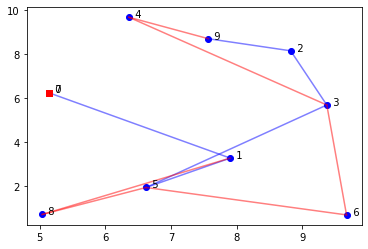

In [2908]:
####drone(scen_12_cust_20-2IFdisratt15v3-2drolling)
#Plotting the n nodes without the node 0 (depot) and chose the color blue for each node.
plt.scatter(loc_x[1:],loc_y[1:],c='b')
for i in N:
    #plt.annotate('$ % d = % d $' %(i, q[i]),(loc_x[i],loc_y[i]))
    plt.annotate(' % d' %(i),(loc_x[i],loc_y[i]))
for i,j in active_arcs3:
    plt.plot([loc_x[i],loc_x[j]], [loc_y[i],loc_y[j]], c='b',alpha = 0.5)
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
#plt.axis('equal');

for i,j in active_arcs4:
    plt.plot([loc_x[i],loc_x[j]], [loc_y[i],loc_y[j]], c='r',alpha = 0.5)
plt.plot(loc_x[0],loc_y[0],c='r' ,marker='s')
#plt.axis('equal');

In [2909]:
MyReg2

defaultdict(list, {2: [0, 4, 5, 7, 8], 3: [1, 2, 3, 6, 9], 1: []})

In [1754]:
z1[0,4]+z1[4,3]

13.368